# Machine Learning Projects: Nine Tasks, Four Datasets

A beginner-friendly notebook that walks through nine classic machine-learning tasks (preprocessing, linear regression, KNN, logistic regression, decision trees, K-Means, random forest, SVM and a neural network) using the four datasets supplied with this project.

**How this notebook is written**
- Short code cells that do one thing at a time.
- A Markdown explanation before each major step, and an explanation of the *actual* output after it.
- Every task ends with a **"How to Explain This Model"** box so you can present it to a teacher, classmate or interviewer.
- All numbers in the explanations come from real runs of the code (random seed 42). If you change the seed, a library version or the data, your numbers may differ a little and you should re-read the explanations against your own output.

## Objectives and learning outcomes

By the end of this notebook you should be able to:
1. Inspect a dataset and decide which machine-learning task it is (and is not) suitable for.
2. Clean data, encode categories and scale numbers **without leaking information from the test set**.
3. Train, evaluate and interpret: linear regression, KNN, logistic regression, decision trees, K-Means, random forests, SVMs and a small neural network.
4. Choose evaluation metrics that fit the problem (MSE and R-squared for regression; accuracy, precision, recall, F1 and ROC-AUC for classification; inertia and silhouette for clustering).
5. Explain in plain English what each model does, how it learns and where it can fail.

## 1. Imports, dependencies and reproducibility

**Install (only if something is missing):**
```
pip install pandas numpy scikit-learn matplotlib seaborn tensorflow
```
TensorFlow is only needed for Task 9 (the neural network). Everything else uses the other packages.

**Reproducibility:** we fix the random seed (`SEED = 42`) so that train/test splits, tree building and K-Means start points are the same every time you run the notebook.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, TimeSeriesSplit
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.metrics import (mean_squared_error, r2_score, accuracy_score, precision_score,
                             recall_score, f1_score, confusion_matrix, classification_report,
                             roc_auc_score, roc_curve, silhouette_score, adjusted_rand_score)

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

# We will store one summary line per task here, for the final comparison table.
results = []

## 2. Configuration: where are the data files?

Change the folder or file names in the next cell if your files are somewhere else.

- **Local Jupyter / JupyterLab:** unzip `datasets.zip` so that a folder called `datasets` sits next to this notebook.
- **Google Colab:** upload the four CSV files (or the zip) using the optional upload cell below, then set `DATA_FOLDER` to the folder that contains them.

In [2]:
DATA_FOLDER = "datasets"                       # folder that contains the four CSV files
IRIS_FILE = "1) iris.csv"
STOCK_FILE = "2) Stock Prices Data Set.csv"
HOUSE_FILE = "4) house Prediction Data Set.csv"
SENTIMENT_FILE = "Sentiment dataset.csv"

# Check that every file exists and give a clear message if not.
for file_name in [IRIS_FILE, STOCK_FILE, HOUSE_FILE, SENTIMENT_FILE]:
    path = os.path.join(DATA_FOLDER, file_name)
    if not os.path.exists(path):
        raise FileNotFoundError("Could not find '" + path + "'. Check DATA_FOLDER and the file names above.")
print("All four files found.")

All four files found.


In [3]:
# OPTIONAL (Google Colab only): uncomment to upload files from your computer.
# from google.colab import files
# uploaded = files.upload()      # then set DATA_FOLDER = "."

## 3. Loading and first look at the four datasets

Three of the files are normal CSV files. The **house prices** file is different: it has **no header row** and its columns are separated by spaces, not commas. If we loaded it normally, pandas would use the first house as the column names. So we load it with `header=None` and `sep=r"\s+"`.

The file has 506 rows and 14 columns, which matches the well-known *Boston housing* dataset. The column names below come from that dataset's public documentation. **This is an assumption**: the file itself does not name its columns, so we cross-check it in the next cells (value ranges look right, e.g. `CHAS` is only 0/1, `RM` is about 3.5 to 8.8 rooms).

In [4]:
iris = pd.read_csv(os.path.join(DATA_FOLDER, IRIS_FILE))
stock_raw = pd.read_csv(os.path.join(DATA_FOLDER, STOCK_FILE))
sentiment = pd.read_csv(os.path.join(DATA_FOLDER, SENTIMENT_FILE))

house_columns = ["CRIM", "ZN", "INDUS", "CHAS", "NOX", "RM", "AGE",
                 "DIS", "RAD", "TAX", "PTRATIO", "B", "LSTAT", "MEDV"]
house = pd.read_csv(os.path.join(DATA_FOLDER, HOUSE_FILE), sep=r"\s+", header=None, names=house_columns)

print("Iris:", iris.shape)
print("Stock prices:", stock_raw.shape)
print("House prices:", house.shape)
print("Sentiment:", sentiment.shape)

Iris: (150, 5)
Stock prices: (497472, 7)
House prices: (506, 14)
Sentiment: (732, 15)


### 3.1 First five rows of each dataset

In [5]:
print("IRIS")
display(iris.head())
print("STOCK PRICES")
display(stock_raw.head())
print("HOUSE PRICES")
display(house.head())
print("SENTIMENT")
display(sentiment.head())

IRIS
   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa
STOCK PRICES
  symbol        date      open      high       low     close    volume
0    AAL  2014-01-02   25.0700   25.8200   25.0600   25.3600   8998943
1   AAPL  2014-01-02   79.3828   79.5756   78.8601   79.0185  58791957
2    AAP  2014-01-02  110.3600  111.8800  109.2900  109.7400    542711
3   ABBV  2014-01-02   52.1200   52.3300   51.5200   51.9800   4569061
4    ABC  2014-01-02   70.1100   70.2300   69.4800   69.8900   1148391
HOUSE PRICES
      CRIM    ZN  INDUS  CHAS    NOX     RM   AGE     DIS  RAD    TAX  PTRATIO       B  LSTAT  MEDV
0  0.00632  18.0   2.31     0  0.538  6.575  65.2  4.0900  

### 3.2 Data types, missing values and duplicates

In [6]:
datasets = {"Iris": iris, "Stock prices": stock_raw, "House prices": house, "Sentiment": sentiment}

summary_rows = []
for name, df in datasets.items():
    summary_rows.append({
        "dataset": name,
        "rows": df.shape[0],
        "columns": df.shape[1],
        "numeric columns": df.select_dtypes(include="number").shape[1],
        "text columns": df.shape[1] - df.select_dtypes(include="number").shape[1],
        "missing values": int(df.isna().sum().sum()),
        "duplicate rows": int(df.duplicated().sum()),
    })
display(pd.DataFrame(summary_rows))

        dataset    rows  columns  numeric columns  text columns  missing values  duplicate rows
0          Iris     150        5                4             1               0               3
1  Stock prices  497472        7                5             2              27               0
2  House prices     506       14               14             0               0               0
3     Sentiment     732       15                8             7               0               0


In [7]:
# The sentiment file has two leftover index columns ("Unnamed: ..."). They make every row look unique,
# so we drop them before counting real duplicates.
sentiment_no_index = sentiment.drop(columns=["Unnamed: 0.1", "Unnamed: 0"])
print("Sentiment duplicate rows after dropping index columns:", sentiment_no_index.duplicated().sum())

# Stock: are there repeated (symbol, date) pairs?
print("Stock duplicate (symbol, date) pairs:", stock_raw.duplicated(["symbol", "date"]).sum())
print("Stock: number of different companies (symbols):", stock_raw["symbol"].nunique())
print("Stock: date range:", stock_raw["date"].min(), "to", stock_raw["date"].max())

Sentiment duplicate rows after dropping index columns: 20
Stock duplicate (symbol, date) pairs: 0
Stock: number of different companies (symbols): 505
Stock: date range: 2014-01-02 to 2017-12-29


### 3.3 Missing values in the stock data

open    11
high     8
low      8
dtype: int64


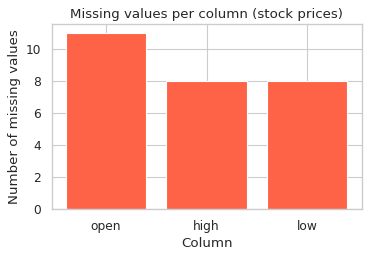

In [8]:
missing_counts = stock_raw.isna().sum()
missing_counts = missing_counts[missing_counts > 0]
print(missing_counts)

plt.figure(figsize=(5, 3))
plt.bar(missing_counts.index, missing_counts.values, color="tomato")
plt.title("Missing values per column (stock prices)")
plt.xlabel("Column")
plt.ylabel("Number of missing values")
plt.show()

### 3.4 Targets and distributions

Number of different sentiment labels: 191
Records for the 3 most common labels: 126 out of 732
House MEDV: how many values equal the maximum 50.0? 16


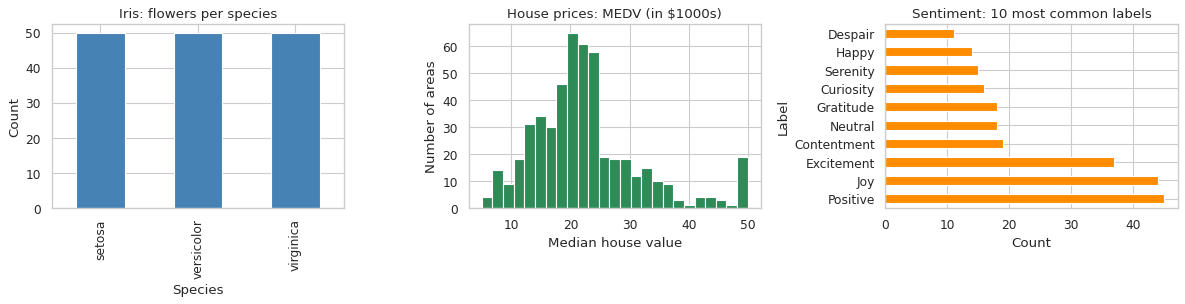

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Iris: how many flowers of each species?
iris["species"].value_counts().plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set_title("Iris: flowers per species")
axes[0].set_xlabel("Species")
axes[0].set_ylabel("Count")

# House: distribution of the median house value (MEDV)
axes[1].hist(house["MEDV"], bins=25, color="seagreen")
axes[1].set_title("House prices: MEDV (in $1000s)")
axes[1].set_xlabel("Median house value")
axes[1].set_ylabel("Number of areas")

# Sentiment: how many flowers... no, how many records per (cleaned) sentiment label? Show the top 10.
sentiment_labels = sentiment["Sentiment"].str.strip()
sentiment_labels.value_counts().head(10).plot(kind="barh", ax=axes[2], color="darkorange")
axes[2].set_title("Sentiment: 10 most common labels")
axes[2].set_xlabel("Count")
axes[2].set_ylabel("Label")
plt.tight_layout()
plt.show()

print("Number of different sentiment labels:", sentiment_labels.nunique())
print("Records for the 3 most common labels:", sentiment_labels.value_counts().head(3).sum(), "out of", len(sentiment))
print("House MEDV: how many values equal the maximum 50.0?", (house["MEDV"] == 50.0).sum())

### What we learned from the inspection (based on the output above)

- **Iris:** 150 rows, 4 numeric measurements and the `species` label (50 flowers each). No missing values, but **3 duplicate rows**.
- **Stock prices:** 497,472 rows for 505 companies from 2014-01-02 to 2017-12-29. Only **27 missing values**, all in `open` (11), `high` (8) and `low` (8). There are no repeated (symbol, date) pairs. It has no ready-made label, so we must create one.
- **House prices:** 506 rows, no missing values, no duplicates. In `MEDV`, **16 areas sit exactly at the cap of 50.0** (the histogram shows a spike at the right edge).
- **Sentiment:** 732 rows but **191 different sentiment labels**. The three most common labels (Positive, Joy, Excitement) cover only 126 of the 732 records, so most labels have very few examples. After dropping the two leftover index columns there are 20 duplicate rows.

## 4. Dataset suitability analysis

Before choosing a dataset for each task we need to know **what each dataset can honestly be used for**.

| Dataset | What it is | Good for | Not good for |
|---|---|---|---|
| **Iris** | 150 flowers, 4 measurements, 3 species | Multiclass classification (KNN, tree), clustering | Regression (no real continuous target), large models |
| **House prices** | 506 areas, 13 features, price `MEDV` | Regression, and binary classification if we label "expensive vs not" | Multiclass classification; very small for a neural network |
| **Stock prices** | about 497,000 daily rows for 505 companies | A *derived* binary target ("does the price go up tomorrow?"), large-sample tasks | Regression on price (too easy and misleading, see below) |
| **Sentiment** | 732 social-media posts with a text label | Text analysis (not asked here) | Classification: 191 different labels, many appear only once or twice |

**Important decisions**
- **House dataset, column `B`:** this column was built from the proportion of Black residents in each area. Using it as a predictor is ethically problematic, so we **exclude it** from all models.
- **House dataset, `MEDV`:** values are capped at 50.0 (shown in the histogram), so the target is slightly "censored". We keep it but keep this in mind.
- **Stock dataset, target:** the file has no label. We create one honestly: `target_up = 1` if the **next day's** close is higher than today's close. All features use only today's and earlier days' data, so there is no look-ahead leakage. We use a sample of companies (30 random ones, plus the few that contain missing values) to keep the notebook fast.
- **Stock dataset, regression:** predicting tomorrow's price from today's price would look impressive (R-squared near 1) but only because prices barely change overnight. That is not real learning, so we avoid it.
- **Sentiment dataset:** with 191 labels we would have to invent our own grouping of emotions into Positive/Negative, which would be inventing labels. We do not use it for the models and explain why.

## 5. Dataset-to-task selection summary

| Task | Dataset | Why |
|---|---|---|
| 1. Preprocessing | Stock prices (company sample) | The only dataset with real missing values, plus a categorical feature (weekday) and numbers on very different scales |
| 2. Linear regression | House prices | Genuine continuous target (`MEDV`) |
| 3. KNN | Iris | Clean labeled multiclass target, small, all numeric |
| 4. Logistic regression | Stock prices | Genuine binary target (price up/down), large sample, mild class imbalance, honest results |
| 5. Decision tree | Iris | Small enough to draw and read the whole tree |
| 6. K-Means | Iris (without labels) | Four meaningful numeric features; labels exist only for an optional comparison afterwards |
| 7. Random forest | Stock prices | Many rows, several features; a good place to see overfitting and feature importance |
| 8. SVM | House prices ("expensive" vs "not") | Binary target; two features (`RM`, `LSTAT`) draw a clear decision boundary |
| 9. Neural network | Stock prices | Needs many rows; the stock sample has tens of thousands |

**Not used for modelling:** the Sentiment dataset (see above).

---
# LEVEL 1: BASIC
---
## Task 1: Data preprocessing for machine learning

**Objective:** turn raw data into a clean numeric table that a model can use, without letting information from the test set sneak into training (this mistake is called **data leakage**).

**Dataset:** Stock prices (a sample of about 35 companies, see Step 1). **Why:** it has real missing values, a categorical column (weekday) and numeric columns on very different scales.

### Step 1: Pick a sample of companies and build features

For each company we sort the rows by date, then create these columns (all using **only today's and past data**):

| Feature | Meaning |
|---|---|
| `return_1d` | percentage change in closing price since yesterday |
| `return_5d` | percentage change since 5 days ago |
| `log_volume_change` | log of (today's volume / yesterday's volume) |
| `range_pct` | (high - low) / close, how much the price moved during the day |
| `open_gap` | today's open compared with yesterday's close |
| `close_vs_avg10` | today's close compared with the 10-day average close |
| `weekday` | Monday ... Friday (categorical) |

The **target** `target_up` is 1 if tomorrow's close is higher than today's close, otherwise 0. We create it with `shift(-1)` (looking one row ahead) and then **remove that helper column** so it cannot be used as a feature.

In [10]:
stock_all = stock_raw.copy()
stock_all["date"] = pd.to_datetime(stock_all["date"])

# Keep only companies that have a (nearly) full history, then take a reproducible random sample of 30.
rows_per_symbol = stock_all["symbol"].value_counts()
full_history_symbols = pd.Series(rows_per_symbol[rows_per_symbol >= 900].index)
random_symbols = full_history_symbols.sample(30, random_state=SEED)

# The 27 missing values sit in only 9 companies, and a random sample can easily miss all of them.
# So we ALSO include the full-history companies that contain missing values, so that Task 1 can show real imputation.
symbols_with_missing = stock_all.loc[stock_all[["open", "high", "low"]].isna().any(axis=1), "symbol"].unique()
extra_symbols = [s for s in symbols_with_missing if s in set(full_history_symbols)]
chosen_symbols = sorted(set(random_symbols) | set(extra_symbols))

print("Number of companies with (nearly) full history:", len(full_history_symbols))
print("Random companies:", len(random_symbols), "| extra companies that contain missing values:", len(extra_symbols))
print("Total companies in our sample:", len(chosen_symbols))

stock = stock_all[stock_all["symbol"].isin(chosen_symbols)].copy()
stock = stock.sort_values(["symbol", "date"]).reset_index(drop=True)
print("Rows in the sample:", len(stock))

Number of companies with (nearly) full history: 485
Random companies: 30 | extra companies that contain missing values: 5
Total companies in our sample: 34
Rows in the sample: 34203


In [11]:
by_company = stock.groupby("symbol")

stock["return_1d"] = by_company["close"].pct_change(1)
stock["return_5d"] = by_company["close"].pct_change(5)
stock["log_volume_change"] = np.log(stock["volume"].replace(0, np.nan) / by_company["volume"].shift(1).replace(0, np.nan))
stock["range_pct"] = (stock["high"] - stock["low"]) / stock["close"]
stock["open_gap"] = stock["open"] / by_company["close"].shift(1) - 1
average_10_days = by_company["close"].rolling(10).mean().reset_index(level=0, drop=True)
stock["close_vs_avg10"] = stock["close"] / average_10_days - 1
stock["weekday"] = stock["date"].dt.day_name()

# Target: is tomorrow's close higher than today's close?
stock["next_close"] = by_company["close"].shift(-1)
stock = stock.dropna(subset=["next_close"])          # the last day of each company has no "tomorrow"
stock["target_up"] = (stock["next_close"] > stock["close"]).astype(int)
stock = stock.drop(columns=["next_close"])           # remove the helper column (it would be leakage!)

# A zero volume would give infinite values; turn any leftovers into missing values.
stock = stock.replace([np.inf, -np.inf], np.nan)

# The first days of each company have no history for the 5-day return / 10-day average: remove them.
stock = stock.dropna(subset=["return_5d", "close_vs_avg10"])

# Sort by date (needed for a fair time-based split later).
stock = stock.sort_values(["date", "symbol"]).reset_index(drop=True)
print("Rows after building features:", len(stock))
display(stock.head())

Rows after building features: 33863
  symbol       date    open    high       low   close    volume  return_1d  return_5d  log_volume_change  range_pct  open_gap  close_vs_avg10    weekday  target_up
0    ADM 2014-01-15   42.43   42.82   42.0950   42.45   4655968   0.002835   0.002125          -0.448902   0.017079  0.002362       -0.001458  Wednesday          0
1   AMAT 2014-01-15   17.72   18.08   17.6900   17.93  11834844   0.017016   0.029277          -0.029373   0.021751  0.005105        0.025216  Wednesday          0
2   AMGN 2014-01-15  118.42  118.95  117.4014  118.51   3065536   0.006711   0.022696           0.187589   0.013067  0.005946        0.016760  Wednesday          1
3    BMY 2014-01-15   55.70   55.72   54.2950   54.50  10144475  -0.021193   0.020217           0.013128   0.026147  0.000359        0.008232  Wednesday          1
4    CAT 2014-01-15   90.88   93.20   90.8800   92.41  10125882   0.020428   0.036684           1.003380   0.025106  0.003534        0.027371  W

### Step 2: Choose features and target, and check data quality

`X` holds the **input features** the model learns from. `y` is the **target** (what we want to predict). We also look at missing values, duplicates and the class balance of the target.

In [12]:
numeric_features = ["return_1d", "return_5d", "log_volume_change", "range_pct", "open_gap", "close_vs_avg10"]
categorical_features = ["weekday"]
feature_names_raw = numeric_features + categorical_features

X = stock[feature_names_raw]
y = stock["target_up"]

print("Missing values per feature:")
print(X.isna().sum())
print()
print("Duplicate rows in the sample (symbol + date):", stock.duplicated(["symbol", "date"]).sum())
print()
print("Share of days where the price went up the next day:", round(y.mean(), 3))
print("Share of days where it went down or stayed the same:", round(1 - y.mean(), 3))

Missing values per feature:
return_1d            0
return_5d            0
log_volume_change    4
range_pct            4
open_gap             7
close_vs_avg10       0
weekday              0
dtype: int64

Duplicate rows in the sample (symbol + date): 0

Share of days where the price went up the next day: 0.516
Share of days where it went down or stayed the same: 0.484


### Step 3: Split into training and test sets (by date)

For stock data the order of time matters. If we shuffled randomly, the model could train on days from *after* the test days, which is cheating. So we train on everything **before 2017** and test on **2017**.

**Duplicates:** there are no duplicate (symbol, date) rows, so we have nothing to remove here. (We *did* remove duplicates for Iris, see Task 3.)

In [13]:
split_date = pd.Timestamp("2017-01-01")
is_train = stock["date"] < split_date

X_train = X[is_train]
X_test = X[~is_train]
y_train = y[is_train]
y_test = y[~is_train]

print("Training rows:", len(X_train), "| dates", stock.loc[is_train, "date"].min().date(), "to", stock.loc[is_train, "date"].max().date())
print("Test rows:", len(X_test), "| dates", stock.loc[~is_train, "date"].min().date(), "to", stock.loc[~is_train, "date"].max().date())

Training rows: 25363 | dates 2014-01-15 to 2016-12-30
Test rows: 8500 | dates 2017-01-03 to 2017-12-28


### Step 4: Build the preprocessing steps

We use a **ColumnTransformer**, which applies different steps to different columns, and a **Pipeline**, which chains steps together.

- **Numeric columns:** fill missing values with the **median** (the middle value, not affected by extreme values), then **standardize** (subtract the mean and divide by the standard deviation, so every column is on a similar scale).
- **Categorical column (`weekday`):** fill missing values with the **most frequent** value, then **one-hot encode** (turn each weekday into its own 0/1 column).

The key safety rule: the preprocessor is **fitted (`fit`) on the training data only**. It learns the medians, means and weekday categories from the training data, then simply applies them (`transform`) to the test data.

In [14]:
numeric_steps = Pipeline([
    ("fill_missing", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])

categorical_steps = Pipeline([
    ("fill_missing", SimpleImputer(strategy="most_frequent")),
    ("one_hot", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer([
    ("numbers", numeric_steps, numeric_features),
    ("categories", categorical_steps, categorical_features),
])

# fit on training data ONLY, then transform both sets
X_train_ready = preprocessor.fit_transform(X_train)
X_test_ready = preprocessor.transform(X_test)

ready_names = preprocessor.get_feature_names_out()
X_train_ready_df = pd.DataFrame(X_train_ready, columns=ready_names)
print("Before preprocessing:", X_train.shape, "| After preprocessing:", X_train_ready.shape)
print("Missing values after preprocessing:", int(np.isnan(X_train_ready).sum()))

Before preprocessing: (25363, 7) | After preprocessing: (25363, 11)
Missing values after preprocessing: 0


### Step 5: Before and after

In [15]:
print("BEFORE (raw training features):")
display(X_train.head())
print("AFTER (imputed, scaled and one-hot encoded):")
display(X_train_ready_df.head().round(3))

print("Means and standard deviations of the numeric columns AFTER scaling (training set):")
display(X_train_ready_df[["numbers__" + name for name in numeric_features]].agg(["mean", "std"]).round(3))

print("Means of the same columns on the TEST set (they will NOT be exactly 0 and 1, which is correct):")
X_test_ready_df = pd.DataFrame(X_test_ready, columns=ready_names)
display(X_test_ready_df[["numbers__" + name for name in numeric_features]].agg(["mean", "std"]).round(3))

BEFORE (raw training features):
   return_1d  return_5d  log_volume_change  range_pct  open_gap  close_vs_avg10    weekday
0   0.002835   0.002125          -0.448902   0.017079  0.002362       -0.001458  Wednesday
1   0.017016   0.029277          -0.029373   0.021751  0.005105        0.025216  Wednesday
2   0.006711   0.022696           0.187589   0.013067  0.005946        0.016760  Wednesday
3  -0.021193   0.020217           0.013128   0.026147  0.000359        0.008232  Wednesday
4   0.020428   0.036684           1.003380   0.025106  0.003534        0.027371  Wednesday
AFTER (imputed, scaled and one-hot encoded):
   numbers__return_1d  numbers__return_5d  numbers__log_volume_change  numbers__range_pct  numbers__open_gap  numbers__close_vs_avg10  categories__weekday_Friday  categories__weekday_Monday  categories__weekday_Thursday  categories__weekday_Tuesday  categories__weekday_Wednesday
0               0.127               0.009                      -1.119              -0.307        

### What the output shows

- **Shape:** the training table went from **7 raw columns to 11 model-ready columns**: 6 numeric columns plus 5 weekday columns created by one-hot encoding (Monday to Friday). No missing values remain.
- **Missing values:** in the whole sample the raw features had a few gaps (4 in `log_volume_change`, 4 in `range_pct`, 7 in `open_gap`). The median imputer filled them using values learned from the training rows only. These are very few rows; the imputing step matters little for the results, but it shows the correct procedure.
- **Scaling:** on the **training** set every numeric column now has mean 0 and standard deviation 1 (by construction).
- **Test set:** the same columns on the test set are *not* exactly 0 and 1. For example `range_pct` has a mean of about -0.26 and a standard deviation of about 0.65, meaning 2017 was a calmer year (smaller daily price ranges) than 2014 to 2016. This is exactly what we expect when the scaler is fitted on training data only. If the numbers were exactly 0 and 1 on the test set, it would mean we had leaked test information into the scaler.

### How to Explain This Model (Task 1)

- **What it does:** prepares raw data so a model can learn from it: fills gaps, converts categories to numbers, and puts numbers on a common scale.
- **Why it is appropriate:** most models cannot handle missing values or text, and scale-sensitive models (KNN, SVM, logistic regression, neural networks) behave badly when one column has much larger numbers than another.
- **How it "learns":** the preprocessor learns medians, means, standard deviations and category lists from the **training** data only, then applies them to everything.
- **How we check it:** no missing values remain, training columns have mean about 0 and standard deviation about 1.
- **Limitations:** a few extreme values (outliers) still affect the mean and standard deviation. Median imputation treats a missing value as "typical", which may hide real information.

In [16]:
results.append({"Task": "1. Preprocessing", "Dataset": "Stock prices (company sample)", "Algorithm": "Imputer + StandardScaler + OneHotEncoder",
                "Main result": str(X_train.shape[1]) + " raw columns became " + str(X_train_ready.shape[1]) + " model-ready columns, 0 missing"})

---
## Task 2: Simple (multiple) linear regression

**Objective:** predict a continuous number.

**Dataset:** House prices. **Target:** `MEDV`, the median house value in thousands of dollars. **Why:** it is a genuine continuous target.

**Linear regression** finds a straight-line formula: `prediction = intercept + coef1 * feature1 + coef2 * feature2 + ...`. Because we use several features (not just one), this is *multiple* linear regression. It is still a linear regression model.

### Step 1: Choose features and target

`X` = the 12 predictors (all columns except `MEDV` and `B`). `y` = `MEDV`. We exclude `B` for the ethical reason explained in Section 4.

In [17]:
house_features = ["CRIM", "ZN", "INDUS", "CHAS", "NOX", "RM", "AGE", "DIS", "RAD", "TAX", "PTRATIO", "LSTAT"]

print("Missing values in house data:", house.isna().sum().sum())
print("Duplicate rows in house data:", house.duplicated().sum())

X_house = house[house_features]
y_house = house["MEDV"]
display(X_house.head())

Missing values in house data: 0
Duplicate rows in house data: 0
      CRIM    ZN  INDUS  CHAS    NOX     RM   AGE     DIS  RAD    TAX  PTRATIO  LSTAT
0  0.00632  18.0   2.31     0  0.538  6.575  65.2  4.0900    1  296.0     15.3   4.98
1  0.02731   0.0   7.07     0  0.469  6.421  78.9  4.9671    2  242.0     17.8   9.14
2  0.02729   0.0   7.07     0  0.469  7.185  61.1  4.9671    2  242.0     17.8   4.03
3  0.03237   0.0   2.18     0  0.458  6.998  45.8  6.0622    3  222.0     18.7   2.94
4  0.06905   0.0   2.18     0  0.458  7.147  54.2  6.0622    3  222.0     18.7   5.33


**What the columns mean:** `CRIM` crime rate, `ZN` large-lot zoning share, `INDUS` industrial share, `CHAS` borders the river (0/1), `NOX` air pollution, `RM` average rooms per home, `AGE` share of old homes, `DIS` distance to employment centres, `RAD` highway access index, `TAX` property tax rate, `PTRATIO` pupil-teacher ratio, `LSTAT` percent of lower-status population.

### Step 2: Split into training and test sets

We keep 80% of the rows for training and 20% as a test set the model never sees while learning.

In [18]:
X_train_h, X_test_h, y_train_h, y_test_h = train_test_split(X_house, y_house, test_size=0.2, random_state=SEED)
print("Training rows:", len(X_train_h), "| Test rows:", len(X_test_h))

Training rows: 404 | Test rows: 102


### Step 3: Train the model

There are no missing values and no text columns, so no imputing or encoding is needed. Linear regression does not need scaling to make good predictions, so we skip it here (we keep the original units so the coefficients are easier to read).

`fit()` is where the model **learns** the best intercept and coefficients from the training data (it minimizes the squared prediction errors).

In [19]:
linear_model = LinearRegression()
linear_model.fit(X_train_h, y_train_h)

print("Intercept:", round(linear_model.intercept_, 3))
coefficients = pd.DataFrame({"feature": house_features, "coefficient": linear_model.coef_})
coefficients = coefficients.sort_values("coefficient")
display(coefficients.round(3))

Intercept: 36.97
    feature  coefficient
4       NOX      -18.183
7       DIS       -1.466
10  PTRATIO       -0.895
11    LSTAT       -0.538
0      CRIM       -0.127
9       TAX       -0.011
6       AGE       -0.004
2     INDUS        0.025
1        ZN        0.031
8       RAD        0.240
3      CHAS        3.049
5        RM        4.240


### How to read the coefficients

The intercept (about 37.0) is the predicted value ($37,000) for a hypothetical area where every feature is 0. That is not a realistic area, so the intercept mostly just anchors the line.

Each coefficient says: **if this feature rises by 1 unit and everything else stays the same, the predicted house value (in $1000s) changes by this amount.**

- `RM` (+4.24): each extra average room is linked to about **$4,240** higher value.
- `CHAS` (+3.05): areas that border the river are predicted about $3,050 higher.
- `LSTAT` (-0.54): each extra percentage point of lower-status population is linked to about $540 lower value.
- `PTRATIO` (-0.90) and `DIS` (-1.47): more pupils per teacher and greater distance from employment centres are linked to lower values.
- `NOX` (-18.2) looks huge, but `NOX` only ranges from about 0.38 to 0.87, so a "1 unit" change is far larger than anything in the data. **Coefficients on different scales cannot be compared directly.**

These describe associations in this data, not proof of cause and effect.

### Step 4: Predict and evaluate

In [20]:
train_predictions = linear_model.predict(X_train_h)
test_predictions = linear_model.predict(X_test_h)

mse_train = mean_squared_error(y_train_h, train_predictions)
mse_test = mean_squared_error(y_test_h, test_predictions)
r2_train = r2_score(y_train_h, train_predictions)
r2_test = r2_score(y_test_h, test_predictions)

print("Training  MSE:", round(mse_train, 2), "| R-squared:", round(r2_train, 3))
print("Test      MSE:", round(mse_test, 2), "| R-squared:", round(r2_test, 3))
print("Test RMSE (typical error in $1000s):", round(mse_test ** 0.5, 2))

Training  MSE: 22.6 | R-squared: 0.74
Test      MSE: 22.78 | R-squared: 0.689
Test RMSE (typical error in $1000s): 4.77


### Step 5: Plots (actual vs predicted, and residuals)

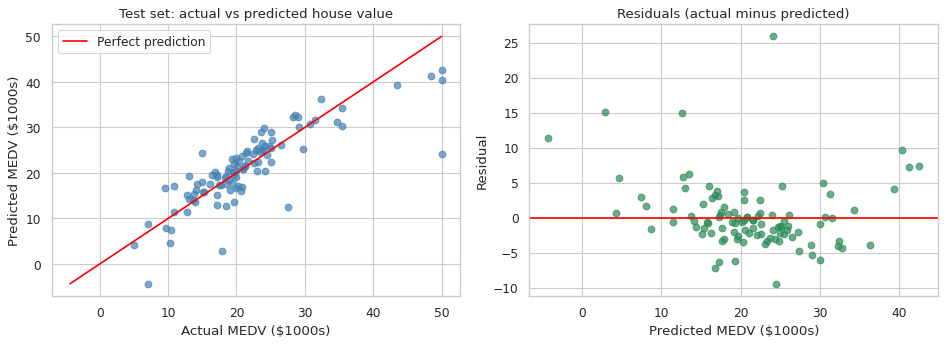

In [21]:
residuals = y_test_h - test_predictions

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].scatter(y_test_h, test_predictions, color="steelblue", alpha=0.7)
low = min(y_test_h.min(), test_predictions.min())
high = max(y_test_h.max(), test_predictions.max())
axes[0].plot([low, high], [low, high], color="red", label="Perfect prediction")
axes[0].set_title("Test set: actual vs predicted house value")
axes[0].set_xlabel("Actual MEDV ($1000s)")
axes[0].set_ylabel("Predicted MEDV ($1000s)")
axes[0].legend()

axes[1].scatter(test_predictions, residuals, color="seagreen", alpha=0.7)
axes[1].axhline(0, color="red")
axes[1].set_title("Residuals (actual minus predicted)")
axes[1].set_xlabel("Predicted MEDV ($1000s)")
axes[1].set_ylabel("Residual")
plt.tight_layout()
plt.show()

### Reading the results

- **R-squared:** about **0.74 on the training set and 0.69 on the test set**. The model explains roughly 69% of the variation in house values on new data. It is a decent but not great fit.
- **MSE:** about 22.6 (train) and 22.8 (test). The test **RMSE is about 4.77**, so a typical prediction is off by roughly **$4,800**. Train and test errors are close, so the model is **not overfitting**; it is limited by being a straight-line model (underfitting to some extent).
- **Actual vs predicted plot:** points follow the red line in the middle (values around 15 to 30) but spread out at the ends. Several of the most expensive areas (actual value 50, the cap) are predicted far lower, and a few predictions are even **negative**, which is impossible for a house value.
- **Residual plot:** residuals curve upward at the very low and very high predictions and one point sits about 26 above zero. A good linear fit would show a shapeless cloud around zero. This curved pattern suggests the true relationship is not perfectly linear, and the capped values at 50 also distort the fit.

**Conclusion:** multiple linear regression gives a useful, easy-to-interpret baseline (test R-squared 0.69), but non-linear effects and the price cap limit its accuracy.

### How to Explain This Model (Task 2)

- **What it does:** fits a straight-line formula that turns features into a predicted number.
- **Why it is appropriate:** the target (house value) is continuous and many features relate to it roughly linearly.
- **How it learns:** it chooses the intercept and coefficients that make the squared errors on the training data as small as possible.
- **Metrics:** MSE (average squared error; lower is better) and R-squared (share of the variation in prices the model explains; 1 is perfect, 0 is no better than predicting the average).
- **Limitations:** it can only draw straight-line relationships, it is sensitive to outliers, and coefficients are only comparable when features are on the same scale.

In [22]:
results.append({"Task": "2. Linear regression", "Dataset": "House prices", "Algorithm": "LinearRegression (12 features)",
                "Main result": "Test R-squared " + str(round(r2_test, 3)) + ", MSE " + str(round(mse_test, 2))})

---
## Task 3: K-Nearest Neighbors (KNN) classifier

**Objective:** classify an iris flower into one of three species.

**Dataset:** Iris. **Why:** a clean labeled multiclass target and four numeric features.

**KNN idea:** to classify a new flower, find the **K most similar flowers** in the training data (smallest distance) and let them vote.

### Step 1: Load, remove duplicates, choose features and target

Iris has 3 exact duplicate rows. We remove them so the same flower cannot appear in both the training and the test set. `X` = the four measurements, `y` = the species.

In [23]:
iris_clean = iris.drop_duplicates().reset_index(drop=True)
print("Rows before:", len(iris), "| rows after removing duplicates:", len(iris_clean))
print(iris_clean["species"].value_counts())

iris_features = ["sepal_length", "sepal_width", "petal_length", "petal_width"]
X_iris = iris_clean[iris_features]
y_iris = iris_clean["species"]
display(X_iris.head())

Rows before: 150 | rows after removing duplicates: 147
species
versicolor    50
virginica     49
setosa        48
Name: count, dtype: int64
   sepal_length  sepal_width  petal_length  petal_width
0           5.1          3.5           1.4          0.2
1           4.9          3.0           1.4          0.2
2           4.7          3.2           1.3          0.2
3           4.6          3.1           1.5          0.2
4           5.0          3.6           1.4          0.2


### Step 2: Split the data

`stratify=y_iris` keeps the species proportions the same in the training and test sets. KNN works with text labels directly, so we do not need to encode the target.

In [24]:
X_train_i, X_test_i, y_train_i, y_test_i = train_test_split(X_iris, y_iris, test_size=0.2, random_state=SEED, stratify=y_iris)
print("Training rows:", len(X_train_i), "| Test rows:", len(X_test_i))

Training rows: 117 | Test rows: 30


### Step 3: Compare several values of K (without touching the test set)

KNN uses distances, so features must be on the same scale. We put a `StandardScaler` and the `KNeighborsClassifier` into one **Pipeline**. When we cross-validate, the scaler is re-fitted inside each fold, so there is no leakage.

To choose K fairly we use **5-fold cross-validation on the training set**: the training data is split into 5 parts, the model trains on 4 and is scored on the 5th, five times. The test set is saved for the very end.

In [25]:
k_values = [1, 3, 5, 7, 9, 11]
knn_rows = []

for k in k_values:
    knn_pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier(n_neighbors=k)),
    ])
    cv_scores = cross_val_score(knn_pipeline, X_train_i, y_train_i, cv=5)
    knn_pipeline.fit(X_train_i, y_train_i)
    knn_rows.append({"K": k,
                     "train accuracy": knn_pipeline.score(X_train_i, y_train_i),
                     "cross-validation accuracy": cv_scores.mean()})

knn_table = pd.DataFrame(knn_rows)
display(knn_table.round(3))

    K  train accuracy  cross-validation accuracy
0   1           1.000                      0.914
1   3           0.957                      0.949
2   5           0.974                      0.949
3   7           0.974                      0.949
4   9           0.957                      0.932
5  11           0.957                      0.941


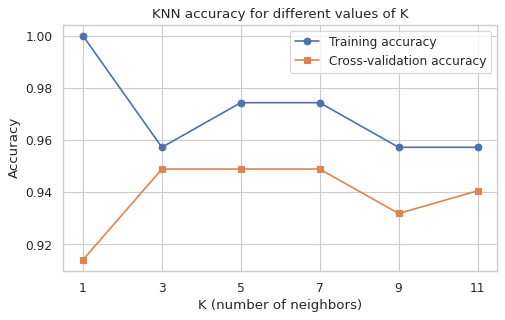

In [26]:
plt.figure(figsize=(7, 4))
plt.plot(knn_table["K"], knn_table["train accuracy"], marker="o", label="Training accuracy")
plt.plot(knn_table["K"], knn_table["cross-validation accuracy"], marker="s", label="Cross-validation accuracy")
plt.title("KNN accuracy for different values of K")
plt.xlabel("K (number of neighbors)")
plt.ylabel("Accuracy")
plt.xticks(k_values)
plt.legend()
plt.show()

### How K affects the results

- **K = 1:** training accuracy is exactly 1.000 (each training flower is its own nearest neighbor) but cross-validation accuracy is lowest (**0.914**). This is classic overfitting: the model follows every quirk of the training data.
- **K = 3, 5 and 7:** all reach the best cross-validation accuracy, **about 0.949**.
- **K = 9 and 11:** cross-validation accuracy drops slightly (0.932 and 0.941), a mild sign that the model is starting to become too smooth.

The differences between K = 3, 5 and 7 are zero in this table, so any of them is a reasonable choice. With only 117 training flowers, small differences like 0.941 vs 0.949 are about one flower and should not be over-interpreted.

### Step 4: Train the chosen model and evaluate it on the test set

We pick the K with the best cross-validation accuracy. If several K values tie, we choose the **largest** tied K, because a larger K gives a smoother, more stable model.

For three classes we use **macro averaging**: compute precision, recall and F1 for each species separately and take the simple average.

In [27]:
best_cv = knn_table["cross-validation accuracy"].max()
best_k = int(knn_table[knn_table["cross-validation accuracy"] == best_cv]["K"].max())
print("Chosen K:", best_k)

final_knn = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=best_k)),
])
final_knn.fit(X_train_i, y_train_i)
knn_predictions = final_knn.predict(X_test_i)

knn_accuracy = accuracy_score(y_test_i, knn_predictions)
knn_precision = precision_score(y_test_i, knn_predictions, average="macro")
knn_recall = recall_score(y_test_i, knn_predictions, average="macro")
knn_f1 = f1_score(y_test_i, knn_predictions, average="macro")

print("Test accuracy :", round(knn_accuracy, 3))
print("Test precision (macro):", round(knn_precision, 3))
print("Test recall (macro)   :", round(knn_recall, 3))
print("Test F1-score (macro) :", round(knn_f1, 3))
print()
print(classification_report(y_test_i, knn_predictions))

Chosen K: 7
Test accuracy : 0.967
Test precision (macro): 0.97
Test recall (macro)   : 0.967
Test F1-score (macro) : 0.967

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.91      1.00      0.95        10
   virginica       1.00      0.90      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



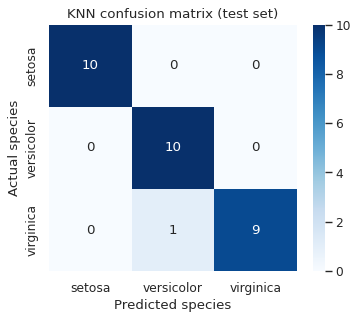

In [28]:
knn_matrix = confusion_matrix(y_test_i, knn_predictions, labels=final_knn.classes_)
plt.figure(figsize=(5, 4))
sns.heatmap(knn_matrix, annot=True, fmt="d", cmap="Blues", xticklabels=final_knn.classes_, yticklabels=final_knn.classes_)
plt.title("KNN confusion matrix (test set)")
plt.xlabel("Predicted species")
plt.ylabel("Actual species")
plt.show()

### Reading the results

We chose **K = 7** (the largest K among the tied best values). On the 30 test flowers:

- **Accuracy 0.967** means 29 of 30 were correct.
- **Macro precision 0.970, macro recall 0.967, macro F1 0.967.**
- The confusion matrix shows the **single mistake**: one *virginica* flower was predicted as *versicolor*. That is why *versicolor* precision is 0.91 and *virginica* recall is 0.90. *Setosa* was classified perfectly.

This matches what we know about Iris: setosa is clearly separate, while versicolor and virginica overlap a little.

**Conclusion:** KNN with scaling works very well on Iris. Because the test set has only 30 flowers, one mistake changes accuracy by 3.3 percentage points, so the score is a rough estimate.

### How to Explain This Model (Task 3)

- **What it does:** classifies a new point by a majority vote among its K closest training points.
- **Why it is appropriate:** Iris classes are well separated in measurement space, and KNN needs no training formula.
- **How it learns:** it does not really learn parameters; it **stores** the training data and looks neighbors up at prediction time. We only choose K.
- **Metrics:** accuracy, precision, recall, F1 (macro-averaged over species) and the confusion matrix.
- **Influence of K:** small K (like 1) follows every quirk of the training data (high variance, can overfit); large K smooths the decision (more stable but can blur real boundaries).
- **Limitations:** needs scaling, slows down on big datasets, and our test set of only 30 flowers is small, so one mistake moves accuracy by about 3 percentage points.

In [29]:
results.append({"Task": "3. KNN", "Dataset": "Iris", "Algorithm": "KNeighborsClassifier (K=" + str(best_k) + ")",
                "Main result": "Test accuracy " + str(round(knn_accuracy, 3)) + ", macro F1 " + str(round(knn_f1, 3))})

---
# LEVEL 2: INTERMEDIATE
---
## Task 4: Logistic regression for binary classification

**Objective:** predict a yes/no outcome: **will the stock's closing price go up tomorrow?** (`target_up`: 1 = up, 0 = not up)

**Dataset:** Stock prices (the same sample, features and date-based split from Task 1). **Why:** a genuine binary target with many rows.

**Logistic regression** is like linear regression, but the result is squeezed through an S-shaped curve (the *sigmoid*) so it becomes a probability between 0 and 1. If the probability is above a **threshold** (0.5 by default) we predict class 1.

### Step 1: Check the class balance

Training target counts (0 = not up, 1 = up):
target_up
1    13024
0    12339
Name: count, dtype: int64
Share of class 1 in training: 0.514
Share of class 1 in test    : 0.524
Accuracy of always guessing the majority class on the test set: 0.524


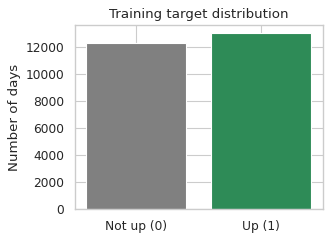

In [30]:
class_counts = y_train.value_counts()
print("Training target counts (0 = not up, 1 = up):")
print(class_counts)
print("Share of class 1 in training:", round(y_train.mean(), 3))
print("Share of class 1 in test    :", round(y_test.mean(), 3))
print("Accuracy of always guessing the majority class on the test set:", round(max(y_test.mean(), 1 - y_test.mean()), 3))

plt.figure(figsize=(4, 3))
plt.bar(["Not up (0)", "Up (1)"], [class_counts[0], class_counts[1]], color=["gray", "seagreen"])
plt.title("Training target distribution")
plt.ylabel("Number of days")
plt.show()

### Class balance

In the training period, **13,024 days were "up" (51.4%)** and 12,339 were not. In the test year, 52.4% of days were "up". The classes are **only slightly imbalanced**, so imbalance itself is not a big problem here.

The important number is the **baseline**: a "model" that always says "up" would be right **52.4%** of the time on the test set. A real model has to beat that to be useful. Accuracy alone can also mislead in the general case: with a 95/5 split, always guessing the majority class would score 95% while finding none of the rare class.

### Step 2: Train the model inside a pipeline

We build a fresh preprocessor (same steps as Task 1) and attach `LogisticRegression` to it. The pipeline fits the preprocessing on the training data only, then trains the model.

In [31]:
log_preprocessor = ColumnTransformer([
    ("numbers", Pipeline([("fill_missing", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), numeric_features),
    ("categories", Pipeline([("fill_missing", SimpleImputer(strategy="most_frequent")), ("one_hot", OneHotEncoder(handle_unknown="ignore"))]), categorical_features),
])

log_model = Pipeline([
    ("preprocess", log_preprocessor),
    ("logistic", LogisticRegression(max_iter=1000, random_state=SEED)),
])
log_model.fit(X_train, y_train)

log_predictions = log_model.predict(X_test)
log_probabilities = log_model.predict_proba(X_test)[:, 1]     # probability of class 1 (price goes up)
print("Done. First 5 predicted probabilities of 'up':", log_probabilities[:5].round(3))

Done. First 5 predicted probabilities of 'up': [0.514 0.524 0.502 0.511 0.519]


### Step 3: Coefficients and odds ratios

A coefficient tells us how the **log-odds** of "up" change when a feature increases by one unit. Taking `exp(coefficient)` gives the **odds ratio**: the multiplier applied to the odds. An odds ratio of 1 means no effect; above 1 raises the odds of "up", below 1 lowers them.

Two cautions: numeric features were **standardized**, so "one unit" means **one standard deviation**; and each weekday coefficient is relative to the other weekdays (all five weekdays appear as columns, and a small penalty built into `LogisticRegression` keeps the coefficients stable).

In [32]:
feature_names_log = log_model.named_steps["preprocess"].get_feature_names_out()
log_coefs = log_model.named_steps["logistic"].coef_[0]

odds_table = pd.DataFrame({"feature": feature_names_log, "coefficient": log_coefs, "odds ratio": np.exp(log_coefs)})
display(odds_table.sort_values("coefficient").round(4))
print("Intercept:", round(log_model.named_steps["logistic"].intercept_[0], 4))

                          feature  coefficient  odds ratio
5         numbers__close_vs_avg10      -0.0498      0.9515
8    categories__weekday_Thursday      -0.0370      0.9636
0              numbers__return_1d      -0.0367      0.9640
3              numbers__range_pct      -0.0348      0.9658
7      categories__weekday_Monday      -0.0095      0.9905
9     categories__weekday_Tuesday       0.0088      1.0089
2      numbers__log_volume_change       0.0094      1.0095
1              numbers__return_5d       0.0276      1.0279
4               numbers__open_gap       0.0358      1.0365
6      categories__weekday_Friday       0.0382      1.0390
10  categories__weekday_Wednesday       0.0440      1.0449
Intercept: 0.0447


### Reading the coefficients and odds ratios

All odds ratios are very close to 1, **between about 0.95 and 1.05**. For example, `close_vs_avg10` has an odds ratio of 0.95: a one-standard-deviation increase in how far today's close is above its 10-day average is linked to about 5% lower odds that the price goes up tomorrow. A tiny hint of "prices that ran up tend to slip back", but the effect is small and we did not test whether it is statistically significant.

Remember: the numeric features were standardized, so "one unit" means one standard deviation. The weekday coefficients are only meaningful relative to each other (Wednesday and Friday slightly higher, Thursday and Monday slightly lower), and they are small.

**Overall:** every effect is tiny. The model found almost no strong relationship between these features and next-day direction.

### Step 4: Evaluate on the test set

In [33]:
log_accuracy = accuracy_score(y_test, log_predictions)
log_precision = precision_score(y_test, log_predictions)
log_recall = recall_score(y_test, log_predictions)
log_f1 = f1_score(y_test, log_predictions)
log_auc = roc_auc_score(y_test, log_probabilities)

print("Accuracy :", round(log_accuracy, 3))
print("Precision:", round(log_precision, 3))
print("Recall   :", round(log_recall, 3))
print("F1-score :", round(log_f1, 3))
print("ROC-AUC  :", round(log_auc, 3))

Accuracy : 0.517
Precision: 0.523
Recall   : 0.901
F1-score : 0.661
ROC-AUC  : 0.494


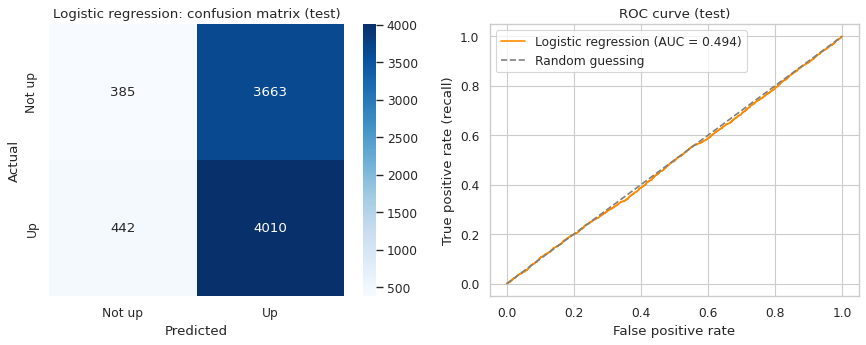

In [34]:
log_matrix = confusion_matrix(y_test, log_predictions)
false_positive_rate, true_positive_rate, thresholds = roc_curve(y_test, log_probabilities)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

sns.heatmap(log_matrix, annot=True, fmt="d", cmap="Blues", ax=axes[0],
            xticklabels=["Not up", "Up"], yticklabels=["Not up", "Up"])
axes[0].set_title("Logistic regression: confusion matrix (test)")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

axes[1].plot(false_positive_rate, true_positive_rate, color="darkorange", label="Logistic regression (AUC = " + str(round(log_auc, 3)) + ")")
axes[1].plot([0, 1], [0, 1], color="gray", linestyle="--", label="Random guessing")
axes[1].set_title("ROC curve (test)")
axes[1].set_xlabel("False positive rate")
axes[1].set_ylabel("True positive rate (recall)")
axes[1].legend()
plt.tight_layout()
plt.show()

### Step 5: How the threshold changes the results

In [35]:
threshold_rows = []
for threshold in [0.45, 0.50, 0.55, 0.60]:
    predicted_class = (log_probabilities >= threshold).astype(int)
    threshold_rows.append({
        "threshold": threshold,
        "predicted 'up' days": int(predicted_class.sum()),
        "accuracy": accuracy_score(y_test, predicted_class),
        "precision": precision_score(y_test, predicted_class, zero_division=0),
        "recall": recall_score(y_test, predicted_class),
    })
display(pd.DataFrame(threshold_rows).round(3))

   threshold  predicted 'up' days  accuracy  precision  recall
0       0.45                 8492     0.524      0.524   0.999
1       0.50                 7673     0.517      0.523   0.901
2       0.55                    6     0.476      0.333   0.000
3       0.60                    0     0.476      0.000   0.000


### Reading the results

- **Accuracy 0.517** is actually **slightly below** the 0.524 you would get by always guessing "up".
- **Precision 0.523, recall 0.901, F1 0.661:** the high recall is misleading. The model's predicted probabilities all sit very close to 0.5 (the first five were all about 0.50 to 0.52), so at the default 0.5 threshold it predicts "up" on 7,673 of 8,500 days. Catching 90% of the "up" days is easy when you predict "up" almost every day, and precision stays near the base rate.
- **ROC-AUC 0.494** is essentially **0.5, which equals random guessing**. The ROC curve hugs the diagonal line. The AUC measures how well the model ranks "up" days above "not-up" days, and here it does not.
- **Threshold table:** the results swing wildly with the threshold. At 0.45 the model predicts "up" almost always (recall 0.999); at 0.55 it predicts "up" on only 6 days; at 0.60 never. The probabilities do not spread out enough for any threshold to help.

**Conclusion:** with these simple features, logistic regression has **no useful predictive power** for next-day direction. This is a reasonable result: daily stock moves are mostly noise, and our features are public, simple price statistics. It is a good reminder that a correctly built pipeline can still honestly report a model that does not work.

### How to Explain This Model (Task 4)

- **What it does:** estimates the probability of a yes/no outcome from a weighted sum of features passed through a sigmoid curve.
- **Why it is appropriate:** the target is binary and we want interpretable coefficients and probabilities.
- **How it learns:** it finds the coefficients that make the predicted probabilities best match the training labels (maximum likelihood).
- **Metrics:** accuracy, precision (of predicted "up" days, how many were up), recall (of real "up" days, how many we found), F1 (balance of both), ROC-AUC (how well it ranks up days above not-up days across all thresholds; 0.5 = random).
- **Limitations:** assumes a straight-line relationship in the log-odds, and daily stock moves are mostly unpredictable noise, so weak results here are expected, not a coding mistake. Accuracy alone can mislead when classes are unbalanced.

In [36]:
results.append({"Task": "4. Logistic regression", "Dataset": "Stock prices (up/down tomorrow)", "Algorithm": "LogisticRegression",
                "Main result": "Test accuracy " + str(round(log_accuracy, 3)) + ", ROC-AUC " + str(round(log_auc, 3))})

---
## Task 5: Decision trees for classification

**Objective:** classify iris species with a tree of if/else questions.

**Dataset:** Iris (duplicates removed). **Why:** small enough that we can draw and read the entire tree.

A **decision tree** repeatedly asks a yes/no question about one feature ("is `petal_length` <= 2.45?") and splits the data into groups that are as *pure* (one species) as possible. The purity measure used here is **Gini impurity** (0 = pure group).

Trees do not need feature scaling, so we skip the scaler. Missing values and categories are not an issue in Iris.

### Step 1: Split the data

In [37]:
X_train_t, X_test_t, y_train_t, y_test_t = train_test_split(X_iris, y_iris, test_size=0.2, random_state=SEED, stratify=y_iris)
print("Training rows:", len(X_train_t), "| Test rows:", len(X_test_t))

Training rows: 117 | Test rows: 30


### Step 2: Baseline tree with no limits

With no restrictions the tree keeps splitting until every training flower is perfectly classified. That usually means it **memorizes** the training data (overfitting).

In [38]:
baseline_tree = DecisionTreeClassifier(random_state=SEED)
baseline_tree.fit(X_train_t, y_train_t)

print("Baseline tree depth:", baseline_tree.get_depth())
print("Baseline tree leaves:", baseline_tree.get_n_leaves())
print("Baseline training accuracy:", round(baseline_tree.score(X_train_t, y_train_t), 3))
print("Baseline cross-validation accuracy:", round(cross_val_score(baseline_tree, X_train_t, y_train_t, cv=5).mean(), 3))

Baseline tree depth: 5
Baseline tree leaves: 8
Baseline training accuracy: 1.0
Baseline cross-validation accuracy: 0.949


### Step 3: How complexity affects generalization

We train trees with `max_depth` from 1 to 8 and compare training accuracy with cross-validation accuracy (scored on training data held out in each fold, never the test set).

   max_depth  train accuracy  cross-val accuracy
0          1           0.667               0.667
1          2           0.966               0.941
2          3           0.983               0.940
3          4           0.991               0.949
4          5           1.000               0.949
5          6           1.000               0.949
6          7           1.000               0.949
7          8           1.000               0.949


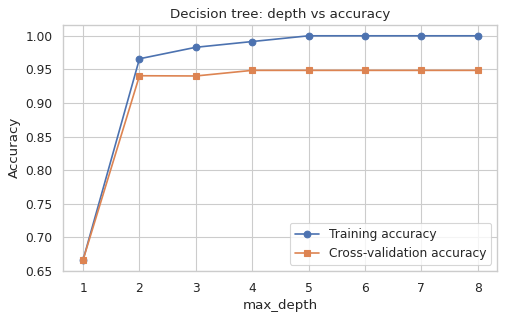

In [39]:
depths = [1, 2, 3, 4, 5, 6, 7, 8]
train_scores = []
cv_means = []

for depth in depths:
    tree = DecisionTreeClassifier(max_depth=depth, random_state=SEED)
    tree.fit(X_train_t, y_train_t)
    train_scores.append(tree.score(X_train_t, y_train_t))
    cv_means.append(cross_val_score(tree, X_train_t, y_train_t, cv=5).mean())

plt.figure(figsize=(7, 4))
plt.plot(depths, train_scores, marker="o", label="Training accuracy")
plt.plot(depths, cv_means, marker="s", label="Cross-validation accuracy")
plt.title("Decision tree: depth vs accuracy")
plt.xlabel("max_depth")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

display(pd.DataFrame({"max_depth": depths, "train accuracy": train_scores, "cross-val accuracy": cv_means}).round(3))

### Step 4: Pruning with cross-validation

We now search a small grid of settings that **limit** the tree (this is called pruning):
- `max_depth`: the deepest the tree may grow.
- `min_samples_leaf`: every final group (leaf) must contain at least this many flowers.
- `ccp_alpha`: *cost-complexity pruning*. Larger values cut away branches that add little accuracy.

`GridSearchCV` tries every combination using 5-fold cross-validation **on the training set only**, then refits the best one.

In [40]:
param_grid = {
    "max_depth": [2, 3, 4, 5, None],
    "min_samples_leaf": [1, 2, 5, 10],
    "ccp_alpha": [0.0, 0.01, 0.02, 0.05],
}
tree_search = GridSearchCV(DecisionTreeClassifier(random_state=SEED), param_grid, cv=5, scoring="accuracy")
tree_search.fit(X_train_t, y_train_t)

pruned_tree = tree_search.best_estimator_
print("Best settings:", tree_search.best_params_)
print("Best cross-validation accuracy:", round(tree_search.best_score_, 3))
print("Pruned tree depth:", pruned_tree.get_depth(), "| leaves:", pruned_tree.get_n_leaves())

Best settings: {'ccp_alpha': 0.0, 'max_depth': 4, 'min_samples_leaf': 1}
Best cross-validation accuracy: 0.949
Pruned tree depth: 4 | leaves: 7


### Step 5: Draw the pruned tree and read its rules

|--- petal_length <= 2.45
|   |--- class: setosa
|--- petal_length >  2.45
|   |--- petal_width <= 1.65
|   |   |--- petal_length <= 4.95
|   |   |   |--- class: versicolor
|   |   |--- petal_length >  4.95
|   |   |   |--- sepal_length <= 6.15
|   |   |   |   |--- class: versicolor
|   |   |   |--- sepal_length >  6.15
|   |   |   |   |--- class: virginica
|   |--- petal_width >  1.65
|   |   |--- petal_length <= 4.85
|   |   |   |--- sepal_width <= 3.00
|   |   |   |   |--- class: virginica
|   |   |   |--- sepal_width >  3.00
|   |   |   |   |--- class: versicolor
|   |   |--- petal_length >  4.85
|   |   |   |--- class: virginica



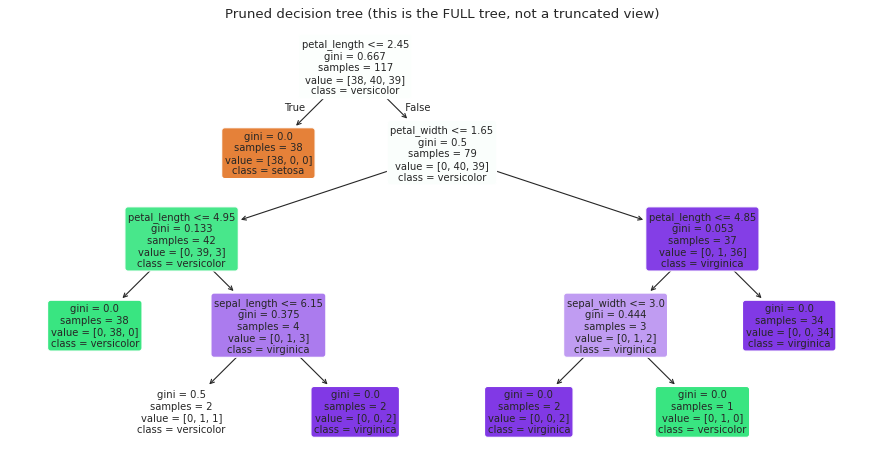

In [41]:
plt.figure(figsize=(14, 7))
plot_tree(pruned_tree, feature_names=iris_features, class_names=list(pruned_tree.classes_), filled=True, rounded=True, fontsize=9)
plt.title("Pruned decision tree (this is the FULL tree, not a truncated view)")
plt.show()

print(export_text(pruned_tree, feature_names=iris_features))

### Reading the tree and the rules

This plot shows the **full** pruned tree (depth 4, 7 leaves), not a truncated view. Each box shows the question asked, the **gini** impurity (0 means all flowers in the box are one species), the number of training **samples**, the **value** (counts of setosa, versicolor, virginica) and the majority **class**.

- **Root split `petal_length <= 2.45`:** this alone separates all 38 setosa flowers into a pure leaf.
- **Next split `petal_width <= 1.65`**, then `petal_length`: these two measurements separate most versicolor from virginica. One leaf holds 38 pure versicolor, another holds 34 pure virginica.
- **Deepest splits** (`sepal_length`, `sepal_width`) decide the fate of only a handful of flowers (groups of 4 and 3). These are the branches most likely to be fitting noise.

Notice that the model mostly relies on **petal** measurements, which agrees with the Task 6 cluster profiles.

### Step 6: Evaluate baseline vs pruned tree on the test set

                  model  accuracy  precision (macro)  recall (macro)  F1 (macro)
0  Baseline (no limits)     0.933              0.933           0.933       0.933
1                Pruned     0.933              0.933           0.933       0.933


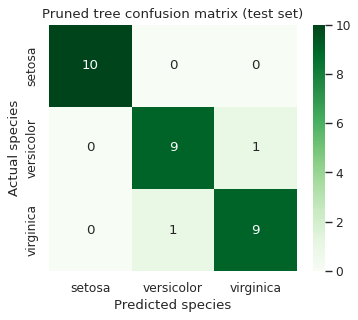

In [42]:
baseline_predictions = baseline_tree.predict(X_test_t)
pruned_predictions = pruned_tree.predict(X_test_t)

tree_rows = []
for name, predictions in [("Baseline (no limits)", baseline_predictions), ("Pruned", pruned_predictions)]:
    tree_rows.append({
        "model": name,
        "accuracy": accuracy_score(y_test_t, predictions),
        "precision (macro)": precision_score(y_test_t, predictions, average="macro"),
        "recall (macro)": recall_score(y_test_t, predictions, average="macro"),
        "F1 (macro)": f1_score(y_test_t, predictions, average="macro"),
    })
tree_table = pd.DataFrame(tree_rows)
display(tree_table.round(3))

tree_matrix = confusion_matrix(y_test_t, pruned_predictions, labels=pruned_tree.classes_)
plt.figure(figsize=(5, 4))
sns.heatmap(tree_matrix, annot=True, fmt="d", cmap="Greens", xticklabels=pruned_tree.classes_, yticklabels=pruned_tree.classes_)
plt.title("Pruned tree confusion matrix (test set)")
plt.xlabel("Predicted species")
plt.ylabel("Actual species")
plt.show()

### Baseline vs pruned tree

- The **unrestricted baseline tree** already had only depth 5 and 8 leaves, because Iris is so easy. It scores 1.000 on the training data but about 0.949 in cross-validation.
- In the depth experiment, accuracy jumps from 0.667 at depth 1 to 0.941 at depth 2 and then barely improves (0.949 from depth 4 onward). Beyond depth 2 to 4 the extra splits only help on the training data (training accuracy goes 0.966 to 1.000) but not on held-out data. This is the complexity trade-off.
- The cross-validated search picked `max_depth=4`, `min_samples_leaf=1`, `ccp_alpha=0`. Many settings tied at 0.949, and `GridSearchCV` keeps the first one it found, so the "best" settings are not special. In other words, **pruning made no measurable difference on this dataset** because the unpruned tree was already small. On bigger and noisier data the gap would be much larger.
- **Test set:** both trees get **accuracy 0.933** (28 of 30 correct), and macro precision, recall and F1 are all 0.933. The confusion matrix shows the 2 mistakes: one versicolor predicted as virginica and one virginica predicted as versicolor (setosa was perfect).

**Conclusion:** a simple tree gets about 93% on new flowers and is fully readable. The slightly lower score than KNN (0.967) is a difference of one flower on a 30-flower test set, so we should **not** say KNN is better.

### How to Explain This Model (Task 5)

- **What it does:** asks a sequence of yes/no questions about features and ends at a leaf that gives a class.
- **Why it is appropriate:** it is easy to read, needs no scaling and handles non-linear patterns.
- **How it learns:** at every node it picks the feature and cut-off that make the child groups purest (lowest Gini impurity), and repeats until it hits a limit.
- **Metrics:** accuracy, macro precision, recall, F1 and a confusion matrix.
- **Complexity trade-off:** a deep tree fits the training data perfectly but may not generalize; a shallow tree is simpler and often as accurate on new data.
- **Limitations:** unstable (small data changes can change the tree), and the iris test set is only 30 flowers so differences of one flower look big.

In [43]:
results.append({"Task": "5. Decision tree", "Dataset": "Iris", "Algorithm": "DecisionTreeClassifier (pruned, CV-tuned)",
                "Main result": "Test accuracy " + str(round(tree_table.loc[1, "accuracy"], 3)) + ", macro F1 " + str(round(tree_table.loc[1, "F1 (macro)"], 3))})

---
## Task 6: K-Means clustering

**Objective:** group iris flowers into clusters **without using the species labels**.

**Dataset:** Iris. **Why:** four meaningful numeric measurements. The `species` column is **excluded** from the features. We only use it at the very end for an optional comparison.

**K-Means idea:** pick K starting centres, assign every flower to the nearest centre, move each centre to the average of its flowers, and repeat until nothing changes.

### Step 1: Select and scale the features

K-Means uses distances, so we scale the four measurements. There is no train/test split in clustering (no target to predict), so we scale the whole table.

In [44]:
X_cluster = iris_clean[iris_features]          # NO species column here
scaler = StandardScaler()
X_cluster_scaled = scaler.fit_transform(X_cluster)
print("Clustering table shape:", X_cluster_scaled.shape)
print("Missing values:", int(np.isnan(X_cluster_scaled).sum()))

Clustering table shape: (147, 4)
Missing values: 0


### Step 2: Elbow method and silhouette score

- **Inertia** (within-cluster sum of squares) = how far flowers are from their own cluster centre. It always decreases as K grows; we look for an "elbow" where adding more clusters stops helping much.
- **Silhouette score** (from -1 to 1) = how well each flower fits its own cluster compared with the nearest other cluster. Higher is better.

   K  inertia  silhouette
0  2  220.859       0.579
1  3  138.258       0.457
2  4  112.908       0.415
3  5   89.888       0.344
4  6   80.845       0.342
5  7   70.013       0.321
6  8   62.107       0.335


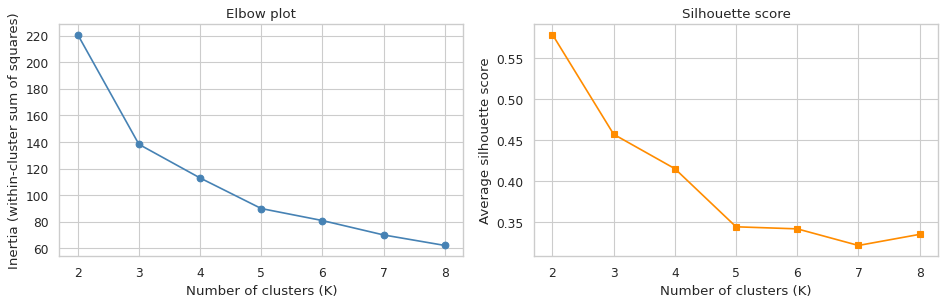

In [45]:
k_range = [2, 3, 4, 5, 6, 7, 8]
inertias = []
silhouettes = []

for k in k_range:
    kmeans_test = KMeans(n_clusters=k, n_init=10, random_state=SEED)
    kmeans_test.fit(X_cluster_scaled)
    inertias.append(kmeans_test.inertia_)
    silhouettes.append(silhouette_score(X_cluster_scaled, kmeans_test.labels_))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(k_range, inertias, marker="o", color="steelblue")
axes[0].set_title("Elbow plot")
axes[0].set_xlabel("Number of clusters (K)")
axes[0].set_ylabel("Inertia (within-cluster sum of squares)")

axes[1].plot(k_range, silhouettes, marker="s", color="darkorange")
axes[1].set_title("Silhouette score")
axes[1].set_xlabel("Number of clusters (K)")
axes[1].set_ylabel("Average silhouette score")
plt.tight_layout()
plt.show()

display(pd.DataFrame({"K": k_range, "inertia": inertias, "silhouette": silhouettes}).round(3))

### Choosing K

- **Elbow plot:** inertia drops sharply from K=2 (220.9) to K=3 (138.3), then decreases more slowly (112.9 at K=4, 89.9 at K=5). There is a gentle bend around **K=3**, but it is not a sharp elbow.
- **Silhouette:** the highest score is at **K=2 (0.579)**, followed by K=3 (0.457). Scores keep falling afterwards.

The two methods do not agree perfectly. K=2 scores best because *setosa* forms one very separate group, while *versicolor* and *virginica* overlap and look like one big group. We choose **K=3** because the elbow bends there and, as a human with extra knowledge, we know the data come from three species. That second reason is outside knowledge, so it is a judgment call, not something the algorithm proved. K=2 is also a defensible answer.

### Step 3: Fit the final model and visualize with PCA

Flowers per cluster: [52 48 47]
Final inertia: 138.26
Final silhouette score: 0.457
Share of the original variation kept by the 2 PCA axes: [0.727 0.23 ] (total 0.958 )


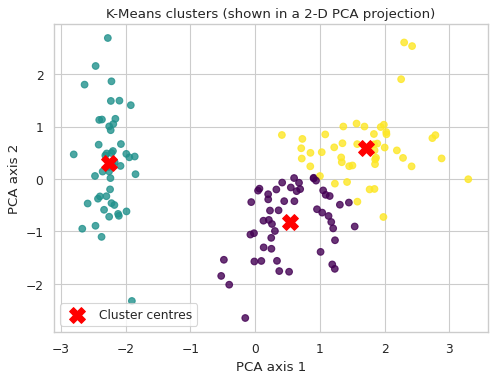

In [46]:
chosen_k = 3

final_kmeans = KMeans(n_clusters=chosen_k, n_init=10, random_state=SEED)
cluster_labels = final_kmeans.fit_predict(X_cluster_scaled)
print("Flowers per cluster:", np.bincount(cluster_labels))
print("Final inertia:", round(final_kmeans.inertia_, 2))
print("Final silhouette score:", round(silhouette_score(X_cluster_scaled, cluster_labels), 3))

# PCA squeezes the 4 scaled features into 2 new axes for plotting only.
pca = PCA(n_components=2, random_state=SEED)
points_2d = pca.fit_transform(X_cluster_scaled)
centers_2d = pca.transform(final_kmeans.cluster_centers_)
print("Share of the original variation kept by the 2 PCA axes:", pca.explained_variance_ratio_.round(3), "(total", round(pca.explained_variance_ratio_.sum(), 3), ")")

plt.figure(figsize=(7, 5))
plt.scatter(points_2d[:, 0], points_2d[:, 1], c=cluster_labels, cmap="viridis", alpha=0.8)
plt.scatter(centers_2d[:, 0], centers_2d[:, 1], c="red", marker="X", s=200, label="Cluster centres")
plt.title("K-Means clusters (shown in a 2-D PCA projection)")
plt.xlabel("PCA axis 1")
plt.ylabel("PCA axis 2")
plt.legend()
plt.show()

**Remember:** this plot is a *projection*. The clusters were found in the full 4-dimensional (scaled) space. PCA only draws a flat picture of that space, so the picture can hide or distort some distances.

### Step 4: Cluster profiles

We calculate the average of each (original, unscaled) measurement for each cluster so the numbers are easy to read in centimetres.

In [47]:
profile_table = X_cluster.copy()
profile_table["cluster"] = cluster_labels
display(profile_table.groupby("cluster").mean().round(2))
print("Number of flowers in each cluster:")
print(profile_table["cluster"].value_counts().sort_index())

         sepal_length  sepal_width  petal_length  petal_width
cluster                                                      
0                5.80         2.67          4.36         1.40
1                5.01         3.43          1.46         0.25
2                6.78         3.10          5.51         1.97
Number of flowers in each cluster:
cluster
0    52
1    48
2    47
Name: count, dtype: int64


### Step 5 (optional, after clustering): compare with the real species

The species labels were **not** used to build the clusters. Here we only check, afterwards, how the clusters line up with them. The **adjusted Rand index** is 1 for a perfect match and about 0 for a random match.

In [48]:
print(pd.crosstab(iris_clean["species"], cluster_labels, rownames=["species"], colnames=["cluster"]))
print()
print("Adjusted Rand index:", round(adjusted_rand_score(iris_clean["species"], cluster_labels), 3))

cluster      0   1   2
species               
setosa       0  48   0
versicolor  39   0  11
virginica   13   0  36

Adjusted Rand index: 0.62


### Reading the results

- **Cluster sizes:** 52, 48 and 47 flowers. Final inertia 138.3, silhouette 0.457 (moderate: clusters are recognizable but not sharply separated).
- **PCA picture:** the two PCA axes keep about **95.8%** of the variation (72.7% + 23.0%), so the 2-D picture is a fairly faithful summary of the 4-D space.
- **Cluster profiles (averages):**
  - **Cluster 1:** small petals (length 1.46, width 0.25) and the widest sepals: small flowers.
  - **Cluster 2:** the largest petals (length 5.51, width 1.97) and longest sepals: large flowers.
  - **Cluster 0:** medium-sized flowers (petal length 4.36, width 1.40).
- **Comparison with the real species (done afterwards, labels were not used for clustering):** cluster 1 contains **exactly the 48 setosa** flowers. Versicolor is split 39 / 11 and virginica 13 / 36 between clusters 0 and 2. The **adjusted Rand index is 0.62**: a clear but imperfect match to the species.

**Limitations:** the clusters are a description of the measurements, not "true" categories. 24 flowers (11 + 13) fall in the overlapping area between versicolor and virginica, and a different K or different scaling would give different groups.

### How to Explain This Model (Task 6)

- **What it does:** splits unlabeled data into K groups of similar items around K centres.
- **Why it is appropriate:** we want to discover structure from measurements alone.
- **How it learns:** it alternates between assigning points to the nearest centre and moving centres to the mean of their points, until stable.
- **Metrics:** inertia (compactness) and silhouette score (separation). There is no accuracy because there are no true answers.
- **Limitations:** you must choose K; it prefers round, equal-sized clusters; results can depend on the starting centres; and clusters are **not objectively correct categories**. Different features, scaling or K would give different groups.

In [49]:
results.append({"Task": "6. K-Means", "Dataset": "Iris (no labels used)", "Algorithm": "KMeans (K=" + str(chosen_k) + ")",
                "Main result": "Silhouette " + str(round(silhouette_score(X_cluster_scaled, cluster_labels), 3)) + ", inertia " + str(round(final_kmeans.inertia_, 1))})

---
# LEVEL 3: ADVANCED
---
## Task 7: Random forest classifier

**Objective:** predict whether the stock's price goes up tomorrow, with many trees voting.

**Dataset:** Stock prices (same features and date-based split as Task 1). **Why:** tens of thousands of rows, several features, and a chance to see overfitting and feature importance.

A **random forest** builds many decision trees, each on a random sample of the rows and a random subset of features, and lets them vote. Averaging many different trees reduces the overfitting of a single tree.

### Step 1: Baseline forest

In [50]:
rf_preprocessor = ColumnTransformer([
    ("numbers", Pipeline([("fill_missing", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), numeric_features),
    ("categories", Pipeline([("fill_missing", SimpleImputer(strategy="most_frequent")), ("one_hot", OneHotEncoder(handle_unknown="ignore"))]), categorical_features),
])

baseline_forest = Pipeline([
    ("preprocess", rf_preprocessor),
    ("forest", RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=-1)),
])
baseline_forest.fit(X_train, y_train)

print("Baseline forest training accuracy:", round(baseline_forest.score(X_train, y_train), 3))

Baseline forest training accuracy: 1.0


### Step 2: Tune a few hyperparameters with time-aware cross-validation

We search a small grid:
- `max_depth`: how deep each tree can grow.
- `min_samples_leaf`: minimum rows in a leaf (bigger = simpler trees).
- `max_features`: how many features each split may consider.

**Cross-validation for time-ordered data:** `TimeSeriesSplit` always trains on earlier dates and validates on later dates (so the model never trains on the future). Because the whole pipeline is inside `GridSearchCV`, imputing and scaling are re-fitted inside every fold, so there is no leakage.

**Scoring metric:** `roc_auc`. It measures how well the model ranks "up" days above "not-up" days across all thresholds, so it does not depend on one cut-off and is not fooled by the slight class imbalance.

In [51]:
forest_pipeline = Pipeline([
    ("preprocess", rf_preprocessor),
    ("forest", RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=-1)),
])

forest_grid = {
    "forest__max_depth": [3, 6, 10],
    "forest__min_samples_leaf": [20, 100],
    "forest__max_features": ["sqrt", 0.5],
}

forest_search = GridSearchCV(forest_pipeline, forest_grid, cv=TimeSeriesSplit(n_splits=3), scoring="roc_auc", n_jobs=1)
forest_search.fit(X_train, y_train)

print("Best settings:", forest_search.best_params_)
print("Best cross-validation ROC-AUC:", round(forest_search.best_score_, 4))

Best settings: {'forest__max_depth': 3, 'forest__max_features': 0.5, 'forest__min_samples_leaf': 20}
Best cross-validation ROC-AUC: 0.5144


### Step 3: Compare baseline and tuned forest on the held-out test set

             model  train accuracy  test accuracy  precision  recall     F1  ROC-AUC
0  Baseline forest           1.000          0.505      0.526   0.558  0.541    0.500
1     Tuned forest           0.534          0.532      0.536   0.806  0.644    0.533


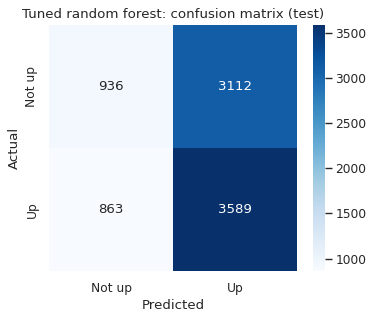

In [52]:
tuned_forest = forest_search.best_estimator_

forest_rows = []
for name, model in [("Baseline forest", baseline_forest), ("Tuned forest", tuned_forest)]:
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]
    forest_rows.append({
        "model": name,
        "train accuracy": model.score(X_train, y_train),
        "test accuracy": accuracy_score(y_test, predictions),
        "precision": precision_score(y_test, predictions, zero_division=0),
        "recall": recall_score(y_test, predictions),
        "F1": f1_score(y_test, predictions),
        "ROC-AUC": roc_auc_score(y_test, probabilities),
    })
forest_table = pd.DataFrame(forest_rows)
display(forest_table.round(3))

forest_predictions = tuned_forest.predict(X_test)
forest_matrix = confusion_matrix(y_test, forest_predictions)
plt.figure(figsize=(5, 4))
sns.heatmap(forest_matrix, annot=True, fmt="d", cmap="Blues", xticklabels=["Not up", "Up"], yticklabels=["Not up", "Up"])
plt.title("Tuned random forest: confusion matrix (test)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

### Step 4: Feature importance

                          feature  importance
0              numbers__return_1d      0.3492
4               numbers__open_gap      0.1992
3              numbers__range_pct      0.1130
5         numbers__close_vs_avg10      0.0984
2      numbers__log_volume_change      0.0915
1              numbers__return_5d      0.0873
6      categories__weekday_Friday      0.0269
9     categories__weekday_Tuesday      0.0104
10  categories__weekday_Wednesday      0.0094
8    categories__weekday_Thursday      0.0092


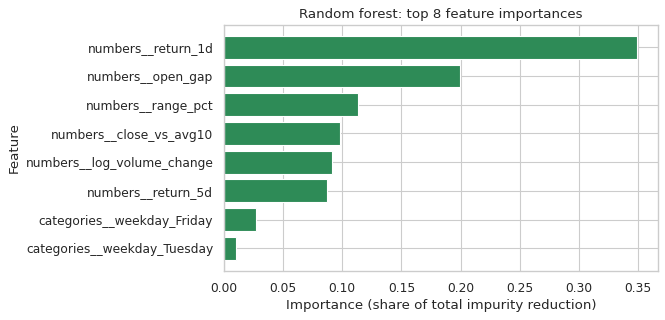

In [53]:
forest_names = tuned_forest.named_steps["preprocess"].get_feature_names_out()
importances = tuned_forest.named_steps["forest"].feature_importances_
importance_table = pd.DataFrame({"feature": forest_names, "importance": importances}).sort_values("importance", ascending=False)
display(importance_table.head(10).round(4))

top_features = importance_table.head(8).sort_values("importance")
plt.figure(figsize=(7, 4))
plt.barh(top_features["feature"], top_features["importance"], color="seagreen")
plt.title("Random forest: top 8 feature importances")
plt.xlabel("Importance (share of total impurity reduction)")
plt.ylabel("Feature")
plt.show()

### Reading the results

- **Baseline forest:** training accuracy **1.000**, but test accuracy only **0.505** and ROC-AUC **0.500**. This is **textbook overfitting**: the trees (grown without depth limits) memorized the training days and learned nothing that carries over to 2017.
- **Tuned forest:** the best settings were shallow trees (`max_depth=3`) with large leaves (`min_samples_leaf=20`). Training accuracy falls to **0.534**, close to the test accuracy of **0.532**, so the gap between them has almost vanished. Test precision is 0.536, recall 0.806, F1 0.644, **ROC-AUC 0.533**. The best cross-validation ROC-AUC during tuning was just 0.514.
- **Compared with the baseline guess:** always predicting "up" scores 0.524, so the tuned forest is only about **0.8 percentage points** better. With daily data shared across stocks, that small gap is not strong evidence of real skill.

**Tuning helped** a lot in terms of overfitting, but it could not create a signal that is barely there. The high recall (0.81) again reflects a model that leans toward predicting "up".

### Feature importance

The most important features are **`return_1d` (0.35)**, **`open_gap` (0.20)** and `range_pct` (0.11); the weekday columns are all at about 0.01 to 0.03. This means the trees used the price-change features most often to split the data.

**Be careful:** importance only says what the model *used*, not what *causes* price moves. Random forests tend to give high importance to continuous features such as returns simply because they offer many possible split points, even when they carry little signal. Given the near-zero ROC-AUC, these importances mostly reflect noise-fitting and should not be read as real drivers of stock prices. Correlated features also share importance.

**Computation:** the search trained 12 settings x 3 folds = 36 forests of 100 trees each plus refits, which is fine on a laptop but grows quickly if you add more settings, trees or folds.

### How to Explain This Model (Task 7)

- **What it does:** trains many different decision trees and combines their votes.
- **Why it is appropriate:** it handles non-linear patterns and many features, and is more stable than one tree.
- **How it learns:** each tree is trained on a random sample of rows and features; the forest averages their predicted probabilities.
- **Metrics:** accuracy, precision, recall, F1, confusion matrix, and ROC-AUC (used also to tune).
- **Feature importance:** shows which features the trees used most to reduce impurity. It does **not** prove cause and effect, can favour features with many distinct values, and can be shared between correlated features.
- **Limitations:** slower and harder to interpret than one tree, can still overfit (compare train vs test), and here the underlying signal is weak because daily price moves are very noisy.

In [54]:
best_forest_row = forest_table.loc[1]
results.append({"Task": "7. Random forest", "Dataset": "Stock prices (up/down tomorrow)", "Algorithm": "RandomForestClassifier (tuned, time-series CV)",
                "Main result": "Test accuracy " + str(round(best_forest_row["test accuracy"], 3)) + ", ROC-AUC " + str(round(best_forest_row["ROC-AUC"], 3))})

---
## Task 8: Support Vector Machine (SVM) for classification

**Objective:** classify whether an area's median house value is **above the median** ("expensive") or not.

**Dataset:** House prices. **Target:** `expensive = 1` if `MEDV` is above the median of all 506 values, else 0. This gives two nearly balanced classes. It is a transformation of a real variable, not invented data.

**No leakage:** `MEDV` (the column that defines the target) and `B` are **removed** from the features. The median is only used to define the label, not as a feature.

**SVM idea:** find the dividing line (or curved boundary) with the **widest margin**, the largest empty gap between the two classes. The training points that touch the margin are the **support vectors**. A **linear** kernel draws a straight boundary; the **RBF** kernel can draw a curved one.

### Step 1: Create the target and split the data

In [55]:
median_value = house["MEDV"].median()
house["expensive"] = (house["MEDV"] > median_value).astype(int)
print("Median MEDV used for the label:", median_value)
print(house["expensive"].value_counts())

X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
    house[house_features], house["expensive"], test_size=0.2, random_state=SEED, stratify=house["expensive"])
print("Training rows:", len(X_train_s), "| Test rows:", len(X_test_s))

Median MEDV used for the label: 21.2
expensive
0    256
1    250
Name: count, dtype: int64
Training rows: 404 | Test rows: 102


### Step 2: Tune the linear and the RBF SVM

SVMs are very sensitive to scale, so each model is a pipeline: `StandardScaler` then `SVC`.

- **C** controls how strictly the model avoids training mistakes. Small C = wider margin, more mistakes allowed (smoother). Large C = narrower margin, fewer training mistakes (risk of overfitting).
- **gamma** (RBF only) controls how far the influence of a single training point reaches. Small gamma = smooth, simple boundary. Large gamma = wiggly boundary that can overfit.

Both are tuned with 5-fold cross-validation on the training set only, scored by ROC-AUC.

In [56]:
linear_pipeline = Pipeline([("scaler", StandardScaler()), ("svm", SVC(kernel="linear"))])
linear_search = GridSearchCV(linear_pipeline, {"svm__C": [0.01, 0.1, 1, 10]}, cv=5, scoring="roc_auc")
linear_search.fit(X_train_s, y_train_s)

rbf_pipeline = Pipeline([("scaler", StandardScaler()), ("svm", SVC(kernel="rbf"))])
rbf_grid = {"svm__C": [0.1, 1, 10, 100], "svm__gamma": [0.001, 0.01, 0.1, 1]}
rbf_search = GridSearchCV(rbf_pipeline, rbf_grid, cv=5, scoring="roc_auc")
rbf_search.fit(X_train_s, y_train_s)

print("Linear SVM best settings:", linear_search.best_params_, "| CV ROC-AUC:", round(linear_search.best_score_, 4))
print("RBF SVM best settings   :", rbf_search.best_params_, "| CV ROC-AUC:", round(rbf_search.best_score_, 4))

Linear SVM best settings: {'svm__C': 1} | CV ROC-AUC: 0.937
RBF SVM best settings   : {'svm__C': 10, 'svm__gamma': 0.1} | CV ROC-AUC: 0.958


### Step 3: Evaluate both models on the same test set

In [57]:
linear_svm = linear_search.best_estimator_
rbf_svm = rbf_search.best_estimator_

svm_rows = []
roc_data = {}
for name, model in [("Linear SVM", linear_svm), ("RBF SVM", rbf_svm)]:
    predictions = model.predict(X_test_s)
    scores = model.decision_function(X_test_s)      # distance from the boundary (used for the ROC curve)
    roc_data[name] = roc_curve(y_test_s, scores)
    svm_rows.append({
        "model": name,
        "accuracy": accuracy_score(y_test_s, predictions),
        "precision": precision_score(y_test_s, predictions),
        "recall": recall_score(y_test_s, predictions),
        "F1": f1_score(y_test_s, predictions),
        "ROC-AUC": roc_auc_score(y_test_s, scores),
        "support vectors": int(model.named_steps["svm"].n_support_.sum()),
    })
svm_table = pd.DataFrame(svm_rows)
display(svm_table.round(3))

        model  accuracy  precision  recall     F1  ROC-AUC  support vectors
0  Linear SVM     0.912      0.918    0.90  0.909    0.964              132
1     RBF SVM     0.892      0.915    0.86  0.887    0.975              126


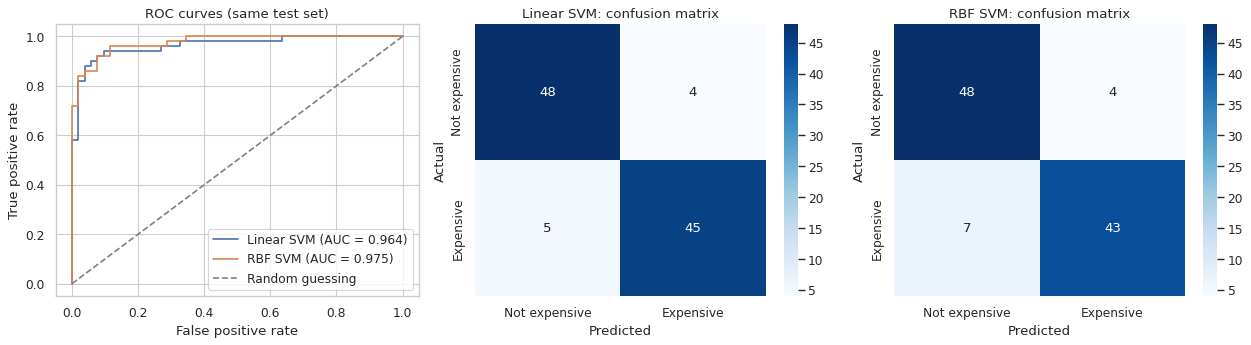

In [58]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for name, (fpr, tpr, thr) in roc_data.items():
    auc_value = svm_table[svm_table["model"] == name]["ROC-AUC"].iloc[0]
    axes[0].plot(fpr, tpr, label=name + " (AUC = " + str(round(auc_value, 3)) + ")")
axes[0].plot([0, 1], [0, 1], color="gray", linestyle="--", label="Random guessing")
axes[0].set_title("ROC curves (same test set)")
axes[0].set_xlabel("False positive rate")
axes[0].set_ylabel("True positive rate")
axes[0].legend()

for position, (name, model) in enumerate([("Linear SVM", linear_svm), ("RBF SVM", rbf_svm)]):
    matrix = confusion_matrix(y_test_s, model.predict(X_test_s))
    sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", ax=axes[position + 1],
                xticklabels=["Not expensive", "Expensive"], yticklabels=["Not expensive", "Expensive"])
    axes[position + 1].set_title(name + ": confusion matrix")
    axes[position + 1].set_xlabel("Predicted")
    axes[position + 1].set_ylabel("Actual")
plt.tight_layout()
plt.show()

### Reading the results

Both models use the same 102 test areas.

| Model | Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|---|
| Linear SVM | 0.912 | 0.918 | 0.900 | 0.909 | 0.964 |
| RBF SVM | 0.892 | 0.915 | 0.860 | 0.887 | 0.975 |

- **Tuning (training data only):** the linear SVM chose C = 1 (CV ROC-AUC 0.937); the RBF SVM chose C = 10 and gamma = 0.1 (CV ROC-AUC 0.958). On cross-validation the RBF model was ahead.
- **Test set:** the two models are very close. The linear model has slightly higher accuracy and F1 (it classified 2 more of the 102 houses correctly), while the RBF model has the higher **ROC-AUC (0.975 vs 0.964)**, so it ranks expensive areas above cheap ones a bit better. With a test set this small, these differences are within normal noise, so we should **not claim a winner**.
- **Support vectors:** 132 (linear) and 126 (RBF) of the 404 training areas, about a third. Many points lie close to or inside the margin, which is expected because "expensive vs not" is a split at the median, so areas near the median are genuinely ambiguous.
- **ROC curves:** both curves rise steeply toward the top-left corner, far above the diagonal. Both models separate expensive from cheaper areas very well.
- **Confusion matrices:** the linear model made 9 mistakes and the RBF model 11 out of 102 areas, spread over both classes.

Compare this with the stock tasks: here the features carry a strong signal (AUC about 0.97), so the models work, while the stock features carried almost none.

### Step 4: Decision boundary on two features (illustration only)

The real models use 12 features, which cannot be drawn. To *see* what an SVM boundary looks like, we train **new, separate** models using only two features: `RM` (rooms) and `LSTAT` (% lower-status population). **This 2-D picture is an illustration and is not the 12-feature model above.** The boundary is drawn on the training points.

Blue = not expensive (0), red = expensive (1). Only a 2-feature illustration.


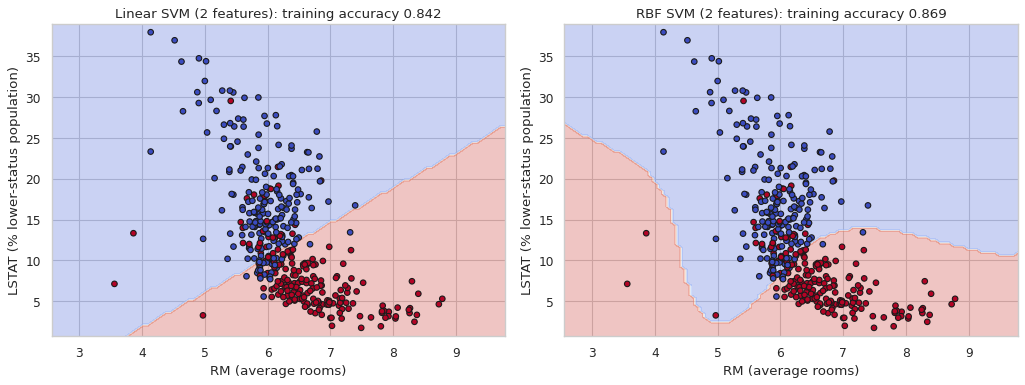

In [59]:
two_features = ["RM", "LSTAT"]
X_train_2d = X_train_s[two_features]

best_c = rbf_search.best_params_["svm__C"]
best_gamma = rbf_search.best_params_["svm__gamma"]

linear_2d = Pipeline([("scaler", StandardScaler()), ("svm", SVC(kernel="linear", C=linear_search.best_params_["svm__C"]))])
rbf_2d = Pipeline([("scaler", StandardScaler()), ("svm", SVC(kernel="rbf", C=best_c, gamma=best_gamma))])
linear_2d.fit(X_train_2d, y_train_s)
rbf_2d.fit(X_train_2d, y_train_s)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for axis, name, model in [(axes[0], "Linear SVM (2 features)", linear_2d), (axes[1], "RBF SVM (2 features)", rbf_2d)]:
    DecisionBoundaryDisplay.from_estimator(model, X_train_2d, response_method="predict", cmap="coolwarm", alpha=0.3, ax=axis)
    axis.scatter(X_train_2d["RM"], X_train_2d["LSTAT"], c=y_train_s, cmap="coolwarm", edgecolor="k", s=25)
    axis.set_title(name + ": training accuracy " + str(round(model.score(X_train_2d, y_train_s), 3)))
    axis.set_xlabel("RM (average rooms)")
    axis.set_ylabel("LSTAT (% lower-status population)")
plt.tight_layout()
plt.show()
print("Blue = not expensive (0), red = expensive (1). Only a 2-feature illustration.")

### What the two-feature picture shows

Remember: this is an illustration using only `RM` and `LSTAT`, **not** the 12-feature models evaluated above.

- **Linear SVM (left):** one straight line. Areas with many rooms and low `LSTAT` (bottom right) are predicted "expensive" (red); the rest "not expensive" (blue). Training accuracy with only these two features is **0.842**.
- **RBF SVM (right):** a curved boundary that hugs the red cluster more closely. Training accuracy is **0.869**, slightly higher because the curve is more flexible.
- Notice that the RBF boundary also curves up into the far-left corner (very few rooms, very low `LSTAT`) and predicts "expensive" in a region where there are almost no training points. This is a reminder that flexible boundaries can behave strangely where there is no data to guide them.
- Even with only two features, the two classes are mostly separable, which agrees with the strong 12-feature results.

### How to Explain This Model (Task 8)

- **What it does:** finds the boundary that separates two classes with the widest possible margin.
- **Why it is appropriate:** it works well on small to medium datasets with many features. Linear kernel = straight boundary; RBF = flexible, curved boundary.
- **How it learns:** it keeps only the *support vectors* (the points closest to the boundary) and chooses the boundary that maximizes the margin while allowing some mistakes (controlled by C; gamma controls RBF flexibility).
- **Metrics:** accuracy, precision, recall, F1, ROC-AUC and confusion matrices on the same test set.
- **Scaling:** essential, because the margin is measured with distances and large-valued features would dominate.
- **Limitations:** slow on very large datasets, sensitive to C and gamma, does not give probabilities directly, and is hard to interpret. The test set has only 102 areas, so small differences between models are not strong evidence.

In [60]:
rbf_row = svm_table[svm_table["model"] == "RBF SVM"].iloc[0]
linear_row = svm_table[svm_table["model"] == "Linear SVM"].iloc[0]
results.append({"Task": "8. SVM", "Dataset": "House prices (expensive vs not)", "Algorithm": "SVC linear vs RBF (CV-tuned)",
                "Main result": "Linear AUC " + str(round(linear_row["ROC-AUC"], 3)) + " / RBF AUC " + str(round(rbf_row["ROC-AUC"], 3)) +
                               "; accuracy " + str(round(linear_row["accuracy"], 3)) + " / " + str(round(rbf_row["accuracy"], 3))})

---
## Task 9: Neural network with TensorFlow/Keras

**Objective:** build a small feed-forward neural network that predicts whether the stock's price goes up tomorrow (binary classification).

**Dataset:** Stock prices (same features as Task 1). **Why:** a neural network needs many rows; the sample has tens of thousands. The other datasets are too small (Iris, House) or have no usable label (Sentiment).

**A neural network** is layers of small units ("neurons"). Each neuron computes a weighted sum of its inputs and passes it through an **activation function**. Training uses **backpropagation**: the network makes predictions, measures the error (the **loss**), and an **optimizer** nudges all the weights to reduce that error, over many passes through the data (**epochs**).

> **Not executed in my environment.** TensorFlow was not installed where this notebook was prepared and there was no internet access to install it, so the cells in this section were **not run** and show no output. All other sections were run. Please run Task 9 yourself (in Google Colab, TensorFlow is preinstalled).

### Step 1: Check that TensorFlow is available

In [ ]:
try:
    import tensorflow as tf
    from tensorflow import keras
    from tensorflow.keras import layers
except ImportError:
    raise ImportError("TensorFlow is not installed. Install it with:  pip install tensorflow   (then restart the kernel). "
                      "Google Colab already includes TensorFlow.")

tf.random.set_seed(SEED)
print("TensorFlow version:", tf.__version__)

### Step 2: Train / validation / test split (by date)

- **Test set:** all of 2017 (same as before, kept untouched until the end).
- **Validation set:** the last 20% of the *training* period (by date). The network uses it after every epoch to check whether it is overfitting.
- **Training set:** the rest.

Preprocessing (imputing, scaling, one-hot) is fitted on the **training part only**.

In [ ]:
train_period = stock[stock["date"] < split_date]
validation_start_date = train_period["date"].quantile(0.8)       # last 20% of the training period

is_nn_train = train_period["date"] < validation_start_date
X_nn_train = train_period.loc[is_nn_train, feature_names_raw]
y_nn_train = train_period.loc[is_nn_train, "target_up"]
X_nn_val = train_period.loc[~is_nn_train, feature_names_raw]
y_nn_val = train_period.loc[~is_nn_train, "target_up"]

print("Train rows:", len(X_nn_train), "| Validation rows:", len(X_nn_val), "| Test rows:", len(X_test))

nn_preprocessor = ColumnTransformer([
    ("numbers", Pipeline([("fill_missing", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), numeric_features),
    ("categories", Pipeline([("fill_missing", SimpleImputer(strategy="most_frequent")), ("one_hot", OneHotEncoder(handle_unknown="ignore"))]), categorical_features),
])
X_nn_train_ready = nn_preprocessor.fit_transform(X_nn_train)      # fit on training part only
X_nn_val_ready = nn_preprocessor.transform(X_nn_val)
X_nn_test_ready = nn_preprocessor.transform(X_test)
print("Input size for the network (number of columns):", X_nn_train_ready.shape[1])

### Step 3: Design the network

- **Input layer:** one input per column (11 in our case: 6 numbers + 5 weekdays).
- **Hidden layer 1:** 16 neurons with **ReLU** activation (outputs `max(0, x)`, a simple, popular choice).
- **Hidden layer 2:** 8 neurons with ReLU.
- **Output layer:** 1 neuron with **sigmoid** activation (gives a probability between 0 and 1 for "price goes up").
- **Loss:** `binary_crossentropy`, the standard loss for yes/no problems (it punishes confident wrong predictions heavily).
- **Optimizer:** `adam`, a widely used method that adjusts the learning rate automatically.

In [ ]:
model = keras.Sequential([
    keras.Input(shape=(X_nn_train_ready.shape[1],)),
    layers.Dense(16, activation="relu"),
    layers.Dense(8, activation="relu"),
    layers.Dense(1, activation="sigmoid"),
])
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
model.summary()

### Step 4: Train with early stopping

`EarlyStopping` watches the validation loss. If it does not improve for 5 epochs, training stops and the weights from the best epoch are restored. This limits overfitting.

In [ ]:
early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)

history = model.fit(
    X_nn_train_ready, y_nn_train.values,
    validation_data=(X_nn_val_ready, y_nn_val.values),
    epochs=50, batch_size=128, callbacks=[early_stop], verbose=0)

print("Training stopped after", len(history.history["loss"]), "epochs")

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history["loss"], label="Training loss")
axes[0].plot(history.history["val_loss"], label="Validation loss")
axes[0].set_title("Loss per epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Binary cross-entropy loss")
axes[0].legend()

axes[1].plot(history.history["accuracy"], label="Training accuracy")
axes[1].plot(history.history["val_accuracy"], label="Validation accuracy")
axes[1].set_title("Accuracy per epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
plt.tight_layout()
plt.show()

### Step 5: Evaluate on the held-out test set

In [ ]:
nn_probabilities = model.predict(X_nn_test_ready, verbose=0).ravel()
nn_predictions = (nn_probabilities >= 0.5).astype(int)

nn_accuracy = accuracy_score(y_test, nn_predictions)
nn_precision = precision_score(y_test, nn_predictions, zero_division=0)
nn_recall = recall_score(y_test, nn_predictions)
nn_f1 = f1_score(y_test, nn_predictions)
nn_auc = roc_auc_score(y_test, nn_probabilities)

print("Test accuracy :", round(nn_accuracy, 3))
print("Test precision:", round(nn_precision, 3))
print("Test recall   :", round(nn_recall, 3))
print("Test F1-score :", round(nn_f1, 3))
print("Test ROC-AUC  :", round(nn_auc, 3))
print("Compare with always guessing the majority class:", round(max(y_test.mean(), 1 - y_test.mean()), 3))

nn_matrix = confusion_matrix(y_test, nn_predictions)
plt.figure(figsize=(5, 4))
sns.heatmap(nn_matrix, annot=True, fmt="d", cmap="Blues", xticklabels=["Not up", "Up"], yticklabels=["Not up", "Up"])
plt.title("Neural network: confusion matrix (test)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

results.append({"Task": "9. Neural network", "Dataset": "Stock prices (up/down tomorrow)", "Algorithm": "Keras Sequential (16-8-1)",
                "Main result": "Test accuracy " + str(round(nn_accuracy, 3)) + ", ROC-AUC " + str(round(nn_auc, 3))})

### How to read your Task 9 results

I could not run this section, so there are no numbers to interpret here. When you run it, check:
- **Loss curves:** if training loss keeps falling while validation loss rises, the network is overfitting; early stopping should stop training near the lowest validation loss.
- **Test metrics vs the majority-class baseline:** the cell prints the accuracy of always guessing the more common class. If your network is not clearly above that baseline and ROC-AUC is near 0.5, it has found little real signal. That is plausible for daily stock direction, and consistent with Tasks 4 and 7.
- **Computational cost:** this network is tiny (a few hundred weights) and trains in seconds on a laptop CPU.

### How to Explain This Model (Task 9)

- **What it does:** passes the features through layers of neurons to output the probability that tomorrow's price is higher.
- **Why it is appropriate:** a feed-forward network can learn non-linear combinations of features and the dataset has enough rows.
- **How it learns:** backpropagation computes how much each weight contributed to the error; the Adam optimizer adjusts weights to reduce binary cross-entropy loss over several epochs.
- **Metrics:** accuracy, precision, recall, F1, plus loss and accuracy curves for training vs validation.
- **Limitations:** needs more data and tuning than simpler models, is hard to interpret, results vary slightly between runs even with a seed, and it cannot create signal that is not in the features.

---
## 6. Cross-task comparison

The table below is filled automatically from the numbers computed above. **Do not compare results across rows as if they were the same test**: different tasks use different datasets, targets and metrics, so only the stock tasks (4, 7, 9) can be compared with each other.

In [61]:
summary_table = pd.DataFrame(results)
display(summary_table)

                     Task                          Dataset                                       Algorithm                                               Main result
0        1. Preprocessing    Stock prices (company sample)        Imputer + StandardScaler + OneHotEncoder    7 raw columns became 11 model-ready columns, 0 missing
1    2. Linear regression                     House prices                  LinearRegression (12 features)                           Test R-squared 0.689, MSE 22.78
2                  3. KNN                             Iris                      KNeighborsClassifier (K=7)                       Test accuracy 0.967, macro F1 0.967
3  4. Logistic regression  Stock prices (up/down tomorrow)                              LogisticRegression                        Test accuracy 0.517, ROC-AUC 0.494
4        5. Decision tree                             Iris       DecisionTreeClassifier (pruned, CV-tuned)                       Test accuracy 0.933, macro F1 0.933
5         

### Compare the stock models fairly (Tasks 4, 7 and 9)

These three models predict the same target on the same 2017 test set, so their ROC-AUC and accuracy values can be compared directly. The next cell collects them.

In [62]:
stock_rows = []
stock_rows.append({"model": "Logistic regression", "test accuracy": log_accuracy, "ROC-AUC": log_auc})
stock_rows.append({"model": "Random forest (tuned)", "test accuracy": forest_table.loc[1, "test accuracy"], "ROC-AUC": forest_table.loc[1, "ROC-AUC"]})
if "nn_accuracy" in globals():
    stock_rows.append({"model": "Neural network", "test accuracy": nn_accuracy, "ROC-AUC": nn_auc})
stock_rows.append({"model": "Always guess majority class", "test accuracy": max(y_test.mean(), 1 - y_test.mean()), "ROC-AUC": 0.5})
display(pd.DataFrame(stock_rows).round(3))

                         model  test accuracy  ROC-AUC
0          Logistic regression          0.517    0.494
1        Random forest (tuned)          0.532    0.533
2  Always guess majority class          0.524    0.500


### What the stock comparison shows

All three stock models (logistic regression, random forest and, when you run it, the neural network) are tested on the same 8,500 days from 2017. The logistic regression (accuracy 0.517, ROC-AUC 0.494) and the tuned random forest (accuracy 0.532, ROC-AUC 0.533) are **both at or very near the "always guess up" baseline of 0.524**, and ROC-AUC values near 0.5 mean they barely rank days better than a coin flip. The random forest's small edge is **not convincing evidence** that it is better.

The neural network row appears here only if you run Task 9; add its numbers to this comparison when you do.

## 7. Key findings, limitations and conclusions

**Key findings**

- **Where the models worked:** Iris (KNN 0.967 and decision tree 0.933 test accuracy, K-Means matching the species with adjusted Rand index 0.62) and the house data (linear regression test R-squared 0.69; SVMs with test ROC-AUC about 0.96 to 0.98). These datasets have clear relationships between features and target.
- **Where they did not:** predicting next-day stock direction from simple price features. Logistic regression (ROC-AUC 0.494) and the tuned random forest (0.533) stayed at about the level of guessing, and the unrestricted random forest memorized the training data (train accuracy 1.000, test 0.505). This is an honest, expected result, not a coding bug.
- **Overfitting lessons:** KNN with K=1, an unlimited random forest, and deeper trees all fit training data better than new data. Cross-validation on training data (never the test set) is how we caught and limited this.
- **Leakage lessons:** scaling inside pipelines, time-ordered splits and cross-validation for stock data, and removing `MEDV` from the SVM features all keep the test results honest.
- **Method vs metric:** a high accuracy means little without a baseline (the 0.524 "always up" guess), and a high recall can be an artifact of predicting one class too often.
- **Data caveats:** the `B` column was excluded for ethical reasons, `MEDV` is capped at 50, and the Sentiment dataset was not usable for supervised learning because it has 191 labels.

**Limitations that remain**
- **Task 9 was not executed** while preparing this notebook (TensorFlow unavailable there, no internet). Its code follows standard Keras usage but is untested by me; please run it and read your own output.
- **House column names are an assumption.** The file has no header; names come from the public Boston housing documentation and were sanity-checked against value ranges.
- **Small test sets** (30 irises, 102 houses) make single-run scores noisy; a different random split could change them noticeably.
- **Stock sample:** we use 30 randomly chosen companies plus 5 chosen because they contain missing values (so the sample is not purely random), covering 2014 to 2017. Results may differ for other companies and years. Features are simple on purpose; this is not a trading system.
- **The Sentiment dataset was not used** for modelling (191 labels, many too rare to learn).
- **Iris** is an easy dataset; high scores there say little about how the same methods would work on harder data.

**Reproducibility notes**
- Random seed 42 everywhere; the notebook was run with the package versions printed in the next cell.
- The stock sample depends on pandas random sampling with `random_state=42`, plus the companies that contain missing values.
- Results can change slightly with different library versions.

**References**
- scikit-learn user guide: https://scikit-learn.org/stable/user_guide.html
- Keras documentation: https://keras.io/api/
- Boston housing dataset documentation (for the column names); note the ethical concerns around the `B` column.
- Fisher, R. A. (1936), the original Iris data paper.

In [63]:
import sklearn
import matplotlib
print("Python packages used:")
print("pandas", pd.__version__, "| numpy", np.__version__, "| scikit-learn", sklearn.__version__, "| matplotlib", matplotlib.__version__, "| seaborn", sns.__version__)
try:
    import tensorflow as tf
    print("tensorflow", tf.__version__)
except ImportError:
    print("tensorflow not installed in this environment")

Python packages used:
pandas 3.0.2 | numpy 2.4.4 | scikit-learn 1.8.0 | matplotlib 3.10.8 | seaborn 0.13.2
tensorflow not installed in this environment
